# Leakage-Aware Evaluation of Explainable and Computationally Efficient Phishing Website Detection Models with Cross-Source Transfer Testing

## Leakage-aware evaluation, statistical uncertainty, and operational relevance

A reproducible experimental workflow for phishing website detection using lightweight, explainable machine-learning models.

**Environment:** Google Colab (CPU only; no GPU required).

**Dataset:** UCI Phishing Websites (repository ID 327), a benchmark of 30 engineered website features. It is not a collection of raw, contemporary URLs, so results on this dataset alone cannot establish real-world or temporal phishing-detection performance. A separate URL-only transfer test on PhreshPhish is included in Section 25.

**Key features**
- Group-aware train/test separation and cross-validation to prevent identical feature vectors from appearing in both training and test partitions.
- Explicit duplicate and conflicting-label audit (records are reported, not silently deleted).
- Cross-validation variability, bootstrap and cluster-bootstrap confidence intervals, paired model comparison, and calibration analysis.
- Hyperparameter optimization and additional baselines (boosting models and a dummy reference).
- SHAP and permutation-based explanations, plus explanation stability across folds.
- Cross-source URL-only transfer test on PhreshPhish.
- Multi-seed, outer-fold, conflict-exclusion, cost-sensitive threshold, and ablation analyses (Sections 34-43).
- Repeated inference-time measurement and a reproducibility record.

**How to run:** open the notebook in Google Colab (or any Jupyter environment with Python 3.10+) and run all cells from top to bottom in a fresh runtime. Section 25 and Section 41 stream data from Hugging Face and require internet access. Results are written to `research_results/`.

> **Note:** Report only values generated by your own run. Do not claim cross-dataset, temporal, campaign-level, or deployment generalization unless it has been tested on suitable independent data.

## 1. Install dependencies

Run this cell once in a fresh Colab runtime.

In [1]:
# Install dependencies
%pip -q install ucimlrepo shap scikit-learn pandas numpy matplotlib seaborn

## 2. Import libraries and set reproducibility options

In [2]:
# Imports, random seed, and output directory
import os
import time
import warnings
import platform
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, matthews_corrcoef,
    confusion_matrix, classification_report, roc_curve,
    precision_recall_curve
)
from sklearn.inspection import permutation_importance
from IPython.display import display

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs("research_results", exist_ok=True)

print("Python:", platform.python_version())
print("scikit-learn:", sklearn.__version__)
print("SHAP:", shap.__version__)
print("Environment initialized. Use CPU; GPU is not required.")

Python: 3.13.18
scikit-learn: 1.6.1
SHAP: 0.54.1
Environment initialized. Use CPU; GPU is not required.


## 3. Download and inspect the UCI dataset

The UCI Phishing Websites dataset uses target labels `-1` (phishing) and `1` (legitimate). In this notebook, **phishing is encoded as 1** and **legitimate as 0**. The mapping is checked below; inspect the printed labels if the dataset version differs.

In [3]:
# Load the UCI dataset and encode the target (1 = phishing, 0 = legitimate)
dataset = fetch_ucirepo(id=327)

X = dataset.data.features.copy()
y_raw = dataset.data.targets.iloc[:, 0]

X = X.apply(pd.to_numeric, errors="coerce")
X = X.dropna(axis=1, how="all")
y_raw = pd.to_numeric(y_raw, errors="coerce")

print("Raw target values:", sorted(y_raw.dropna().unique().tolist()))
print("Feature matrix shape:", X.shape)

# UCI convention: -1 = phishing, +1 = legitimate
if set(y_raw.dropna().unique()).issubset({-1, 1}):
    y = (y_raw == -1).astype(int)
else:
    raise ValueError(
        "Unexpected target labels. Inspect the dataset documentation and "
        "explicitly map phishing to 1 and legitimate to 0 before proceeding."
    )

# Remove rows with missing target values
valid = y_raw.notna()
X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].reset_index(drop=True)

print("\nClass counts (0=legitimate, 1=phishing):")
display(y.value_counts().rename_axis("class").to_frame("count"))
print("Features:", X.shape[1])

Raw target values: [-1, 1]
Feature matrix shape: (11055, 30)

Class counts (0=legitimate, 1=phishing):


,count
class,
0,6157
1,4898


Features: 30


## 4. Audit duplicate feature vectors and conflicting labels

Repeated feature vectors can inflate random-split performance if identical vectors occur in both training and test partitions. We therefore audit them and use feature-vector groups in the split and cross-validation. We do **not** silently discard observations: repeated rows may reflect the original dataset's sampling design. Conflicting labels for identical feature vectors are reported explicitly.

In [4]:
# Hash each feature vector to form groups; identical feature vectors stay in one partition.
from pandas.util import hash_pandas_object

feature_hash = hash_pandas_object(X, index=False).astype("uint64")
groups = pd.Series(feature_hash.to_numpy(), name="feature_group")

audit = pd.DataFrame({"group": groups, "target": y})
group_sizes = audit.groupby("group").size()
label_counts_per_group = audit.groupby("group")["target"].nunique()

print("Original observations retained:", len(X))
print("Unique feature vectors:", groups.nunique())
print("Rows belonging to repeated feature vectors:", int(group_sizes[group_sizes > 1].sum()))
print("Feature vectors with conflicting labels:", int((label_counts_per_group > 1).sum()))
print("Class counts (0=legitimate, 1=phishing):")
display(y.value_counts().rename_axis("class").to_frame("count"))
audit.to_csv("research_results/duplicate_feature_audit.csv", index=False)


Original observations retained: 11055
Unique feature vectors: 5785
Rows belonging to repeated feature vectors: 7884
Feature vectors with conflicting labels: 64
Class counts (0=legitimate, 1=phishing):


,count
class,
0,6157
1,4898


## 5. Explore class distribution

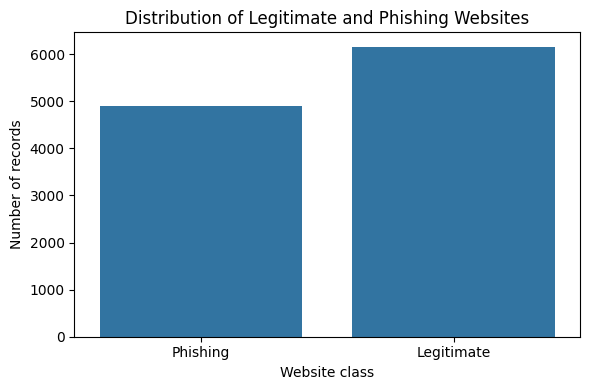

In [5]:
# Class distribution plot
plt.figure(figsize=(6, 4))
sns.countplot(x=y.map({0: "Legitimate", 1: "Phishing"}))
plt.title("Distribution of Legitimate and Phishing Websites")
plt.xlabel("Website class")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

## 6. Create a group-aware held-out test split

All identical feature vectors are assigned to the same partition. This is stricter than a conventional random stratified split and helps reduce optimistic estimates caused by exact feature-vector duplication. The split is approximately 80/20; group constraints may cause modest deviations.

In [6]:
# Group-aware held-out split (first fold = test set)
from sklearn.model_selection import StratifiedGroupKFold

outer_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(outer_splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train, groups_test = groups.iloc[train_idx].copy(), groups.iloc[test_idx].copy()

overlap = set(groups_train).intersection(set(groups_test))
assert len(overlap) == 0, "Leakage audit failed: feature groups overlap across partitions."

print("Training records:", len(X_train), f"({len(X_train)/len(X):.1%})")
print("Test records:", len(X_test), f"({len(X_test)/len(X):.1%})")
print("Feature-group overlap:", len(overlap))
print("Training class proportions:")
display(y_train.value_counts(normalize=True).rename("proportion"))
print("Test class proportions:")
display(y_test.value_counts(normalize=True).rename("proportion"))


Training records: 8898 (80.5%)
Test records: 2157 (19.5%)
Feature-group overlap: 0
Training class proportions:


,proportion
result,
0,0.565183
1,0.434817


Test class proportions:


,proportion
result,
0,0.522949
1,0.477051


## 7. Define lightweight machine-learning pipelines

Preprocessing is inside each pipeline, so imputation and scaling are fitted separately within each training fold. Tree-based methods do not require scaling; Logistic Regression does.

In [7]:
# Model pipelines: preprocessing is fitted inside each training fold to avoid leakage
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1500, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(max_depth=15, random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=150, max_depth=20, n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ]),
    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesClassifier(
            n_estimators=150, max_depth=20, n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ])
}
print("Models:", list(models.keys()))

Models: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Extra Trees']


## 8. Five-fold group-aware cross-validation

Cross-validation is performed on the training partition only. Feature groups are kept intact across folds. Mean and standard deviation across folds are reported; these are descriptive fold-level variability measures, not confidence intervals.

In [8]:
# Group-aware 5-fold cross-validation on the training partition only
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

cv_rows = []
for name, model in models.items():
    print("Group cross-validating:", name)
    start = time.perf_counter()
    scores = cross_validate(
        model, X_train, y_train, groups=groups_train,
        cv=cv, scoring=scoring, n_jobs=1, return_train_score=False
    )
    elapsed = time.perf_counter() - start

    row = {"Model": name, "CV total time (s)": elapsed}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"CV {metric.upper()} mean"] = values.mean()
        row[f"CV {metric.upper()} std"] = values.std(ddof=1)
    cv_rows.append(row)

cv_df = pd.DataFrame(cv_rows)
display(cv_df.round(4))
cv_df.to_csv("research_results/cross_validation_results.csv", index=False)


Group cross-validating: Logistic Regression
Group cross-validating: Decision Tree
Group cross-validating: Random Forest
Group cross-validating: Extra Trees


,Model,CV total time (s),CV ACCURACY mean,CV ACCURACY std,CV PRECISION mean,CV PRECISION std,CV RECALL mean,CV RECALL std,CV F1 mean,CV F1 std,CV ROC_AUC mean,CV ROC_AUC std,CV AVERAGE_PRECISION mean,CV AVERAGE_PRECISION std
0,Logistic Regression,2.9711,0.9223,0.0111,0.9220,0.0180,0.8979,0.0196,0.9096,0.0101,0.9768,0.0058,0.9737,0.0038
1,Decision Tree,2.7718,0.9282,0.0138,0.9172,0.0164,0.9178,0.0175,0.9175,0.0144,0.9412,0.0124,0.8997,0.0194
2,Random Forest,6.1700,0.9528,0.0098,0.9542,0.0168,0.9372,0.0181,0.9454,0.0095,0.9912,0.0034,0.9894,0.0033
3,Extra Trees,7.8949,0.9535,0.0092,0.9504,0.0151,0.9429,0.0167,0.9465,0.0085,0.9916,0.0035,0.9897,0.0036


## 9. Fit models and evaluate on the untouched test set

Inference time is measured for a single batch and divided by the number of test records. It is a machine- and load-dependent measurement; repeat runs if making strong efficiency claims.

In [9]:
# Fit each model on the training set and evaluate once on the held-out test set
results = []
trained_models = {}
test_predictions = {}

for name, model in models.items():
    print("Fitting:", name)
    start = time.perf_counter()
    model.fit(X_train, y_train)
    training_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    inference_total = time.perf_counter() - start

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities),
        "MCC": matthews_corrcoef(y_test, predictions),
        "False Positive Rate": fp / (fp + tn) if (fp + tn) else 0.0,
        "False Negative Rate": fn / (fn + tp) if (fn + tp) else 0.0,
        "Training time (s)": training_time,
        "Inference time (ms/sample)": 1000 * inference_total / len(X_test)
    })

    trained_models[name] = model
    test_predictions[name] = (predictions, probabilities)

results_df = pd.DataFrame(results).sort_values("F1", ascending=False)
display(results_df.round(4))
results_df.to_csv("research_results/test_set_model_comparison.csv", index=False)

Fitting: Logistic Regression
Fitting: Decision Tree
Fitting: Random Forest
Fitting: Extra Trees


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,MCC,False Positive Rate,False Negative Rate,Training time (s),Inference time (ms/sample)
3,Extra Trees,0.9587,0.9537,0.9602,0.9569,0.9929,0.9931,0.9173,0.0426,0.0398,0.8860,0.0656
2,Random Forest,0.9569,0.9579,0.9514,0.9547,0.9921,0.9924,0.9136,0.0381,0.0486,0.8612,0.0571
0,Logistic Regression,0.9356,0.9441,0.9193,0.9316,0.9829,0.9836,0.8710,0.0496,0.0807,0.0472,0.0039
1,Decision Tree,0.9254,0.9474,0.8931,0.9195,0.9542,0.9317,0.8513,0.0452,0.1069,0.0531,0.0033


## 10. Metric comparison plots

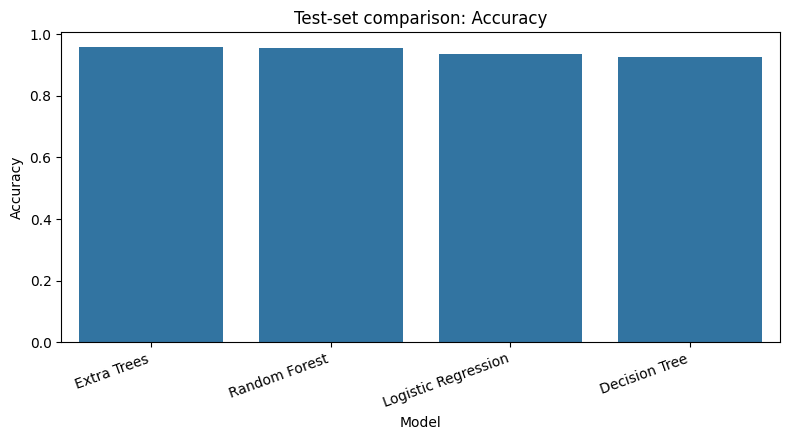

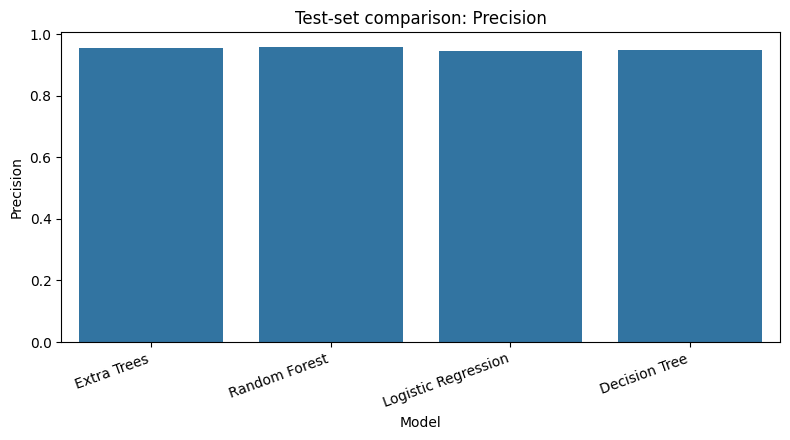

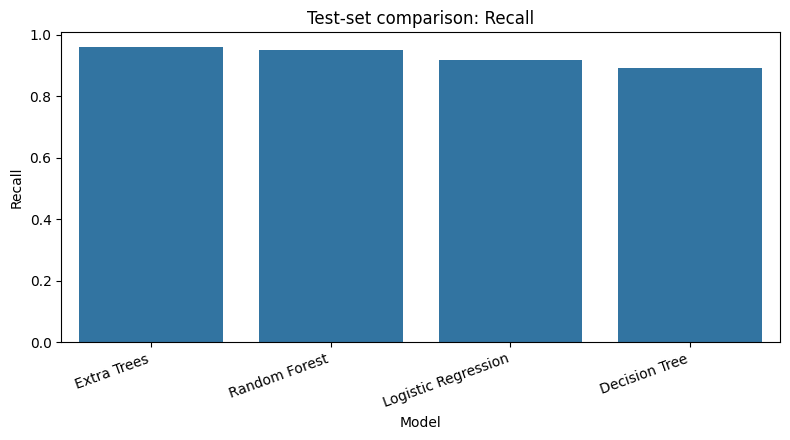

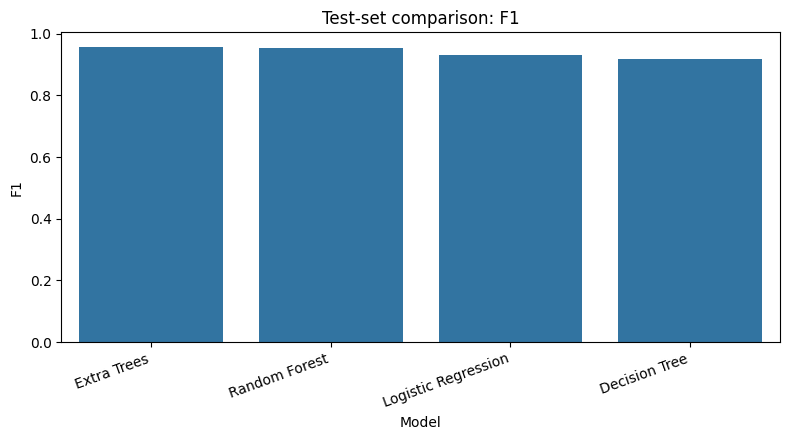

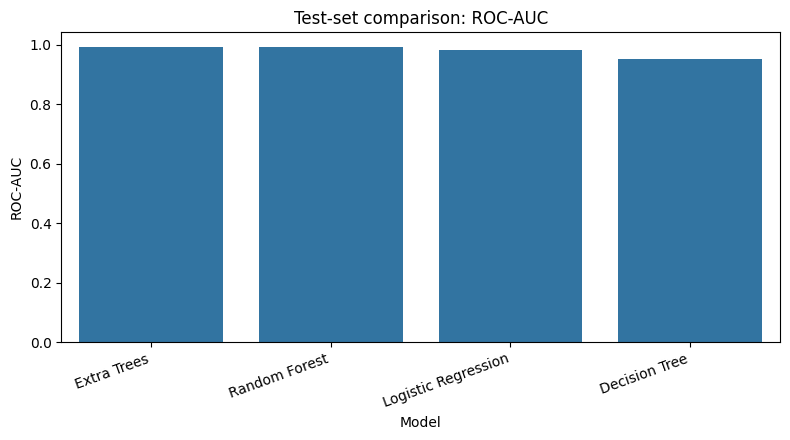

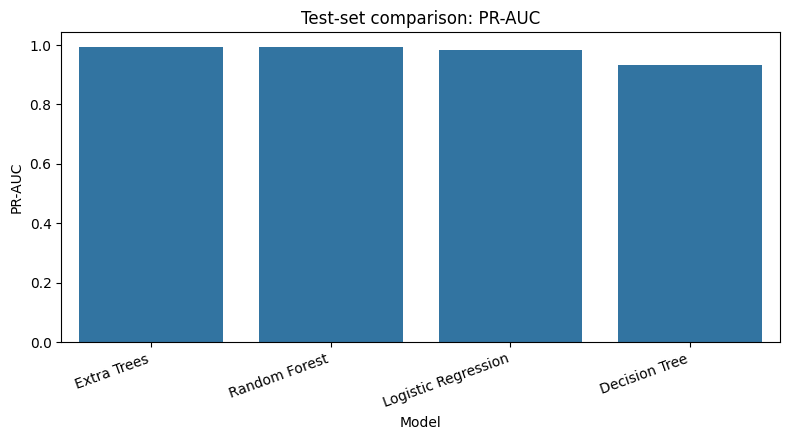

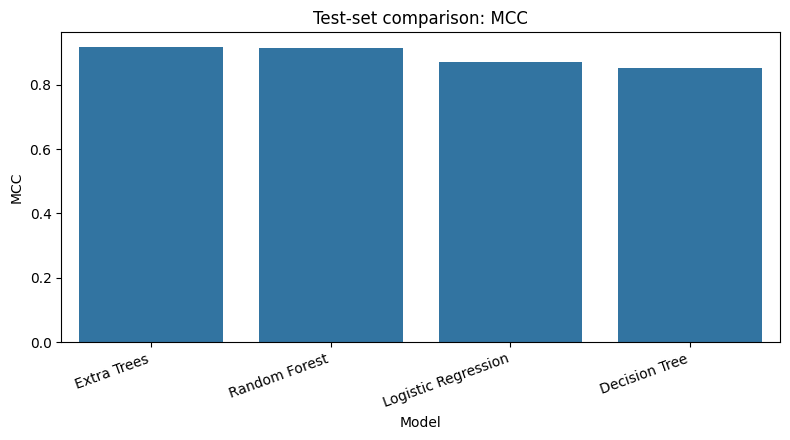

In [10]:
# Bar plots comparing test-set metrics across models
plot_metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "MCC"]

for metric in plot_metrics:
    plt.figure(figsize=(8, 4.5))
    sns.barplot(data=results_df, x="Model", y=metric)
    plt.title(f"Test-set comparison: {metric}")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(f"research_results/{metric.lower().replace('-', '_')}_comparison.png", dpi=300)
    plt.show()

## 11. Confusion matrices

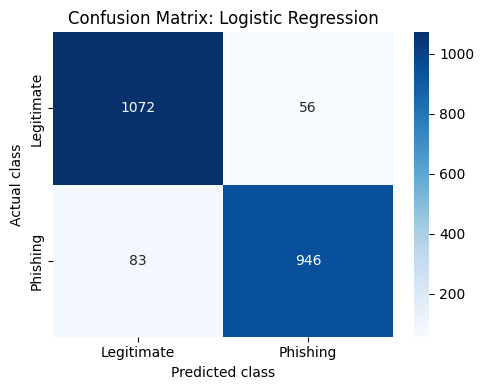

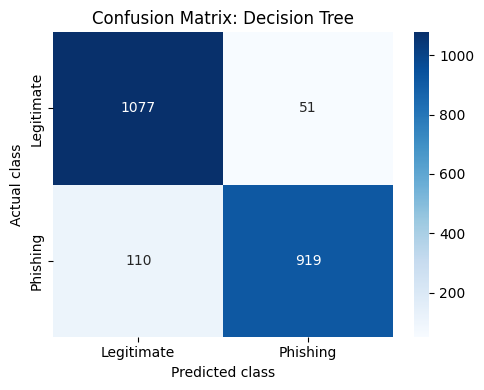

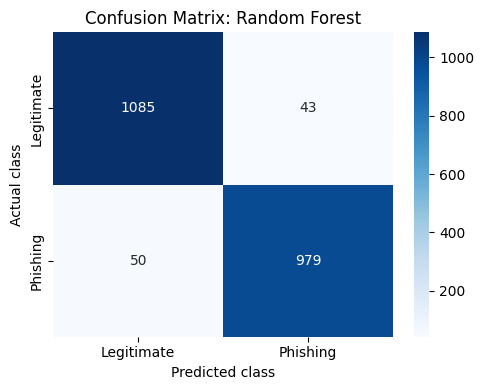

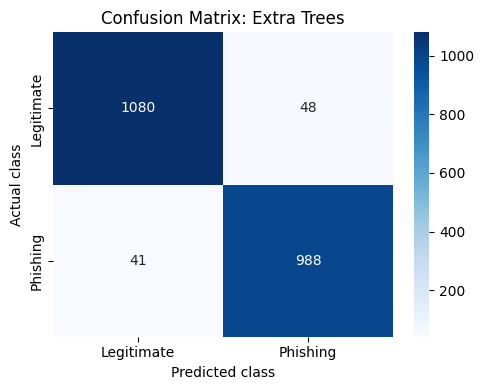

In [11]:
# Confusion matrix for each model
for name, (predictions, probabilities) in test_predictions.items():
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Legitimate", "Phishing"],
        yticklabels=["Legitimate", "Phishing"]
    )
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted class")
    plt.ylabel("Actual class")
    plt.tight_layout()
    plt.savefig(f"research_results/confusion_matrix_{name.replace(' ', '_').lower()}.png", dpi=300)
    plt.show()

## 12. ROC and Precision-Recall curves

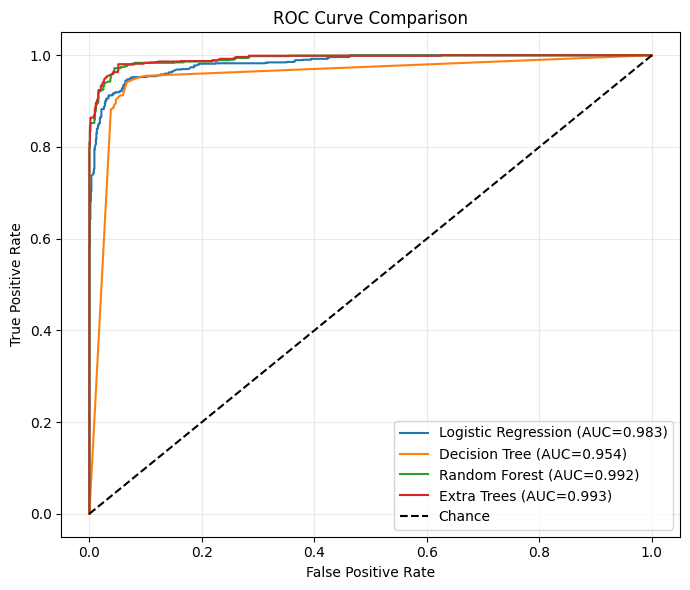

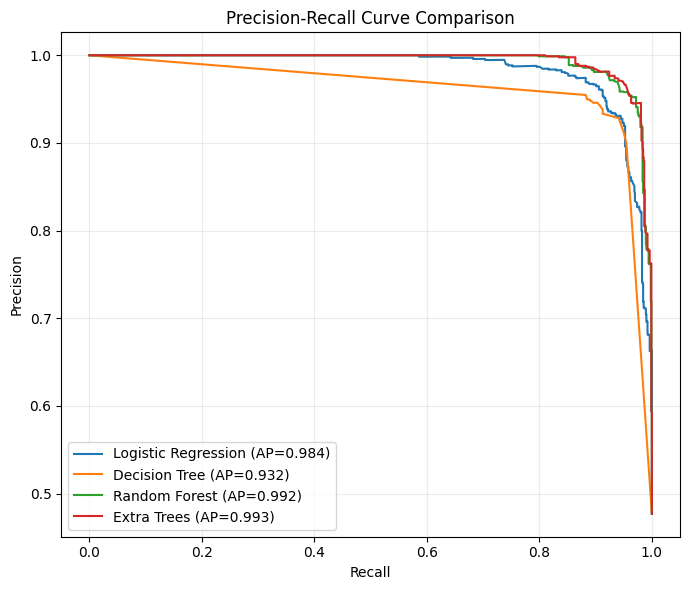

In [12]:
# ROC and precision-recall curves
plt.figure(figsize=(7, 6))
for name, (predictions, probabilities) in test_predictions.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("research_results/roc_curves.png", dpi=300)
plt.show()

plt.figure(figsize=(7, 6))
for name, (predictions, probabilities) in test_predictions.items():
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    ap = average_precision_score(y_test, probabilities)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("research_results/precision_recall_curves.png", dpi=300)
plt.show()

## 13. Select the best tree model for SHAP

Selection is based on group-aware cross-validation F1 on the training partition only. The held-out test set is not used to select the explanation model.

In [13]:
# Select the tree model for SHAP using training cross-validation F1 only
tree_names = ["Decision Tree", "Random Forest", "Extra Trees"]
tree_cv = cv_df[cv_df["Model"].isin(tree_names)].copy()
best_tree_name = tree_cv.sort_values("CV F1 mean", ascending=False).iloc[0]["Model"]

best_pipeline = trained_models[best_tree_name]
tree_estimator = best_pipeline.named_steps["model"]
imputer = best_pipeline.named_steps["imputer"]

# Tree pipelines use median imputation only
X_test_transformed = imputer.transform(X_test)
feature_names = X.columns.tolist()

print("Tree model selected using training cross-validation:", best_tree_name)
print("SHAP sample will be drawn from the held-out test set.")

Tree model selected using training cross-validation: Extra Trees
SHAP sample will be drawn from the held-out test set.


## 14. SHAP global and local explanations

SHAP is computed on a small sample to keep execution practical on Colab Free. The class being explained is **phishing (class 1)**.

SHAP values shape: (250, 30)


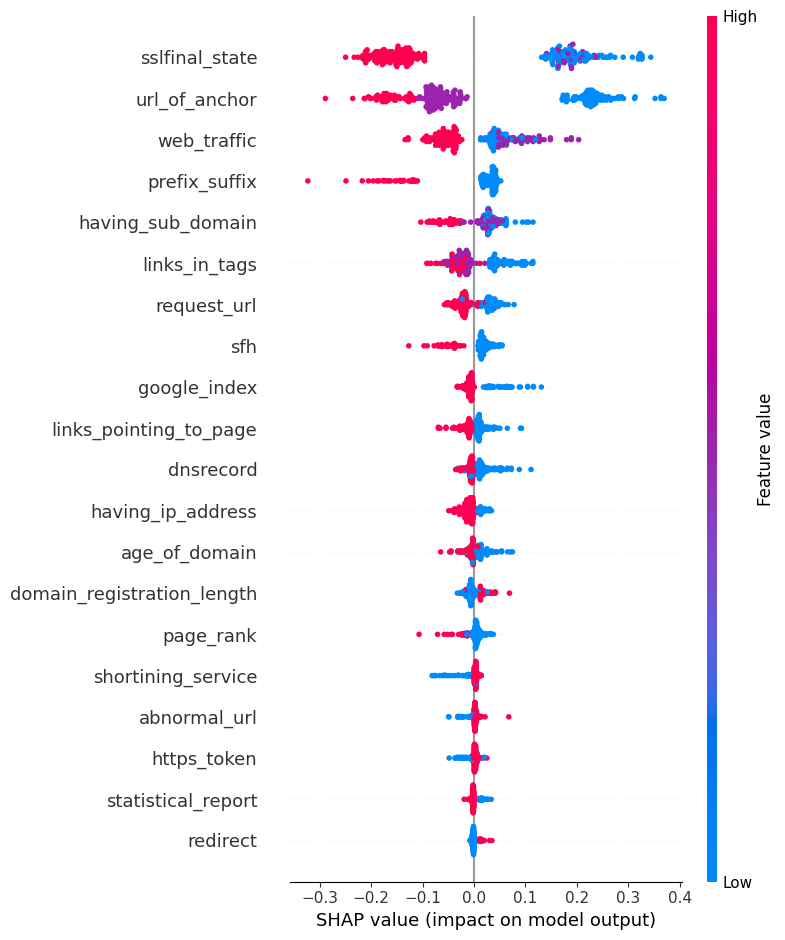

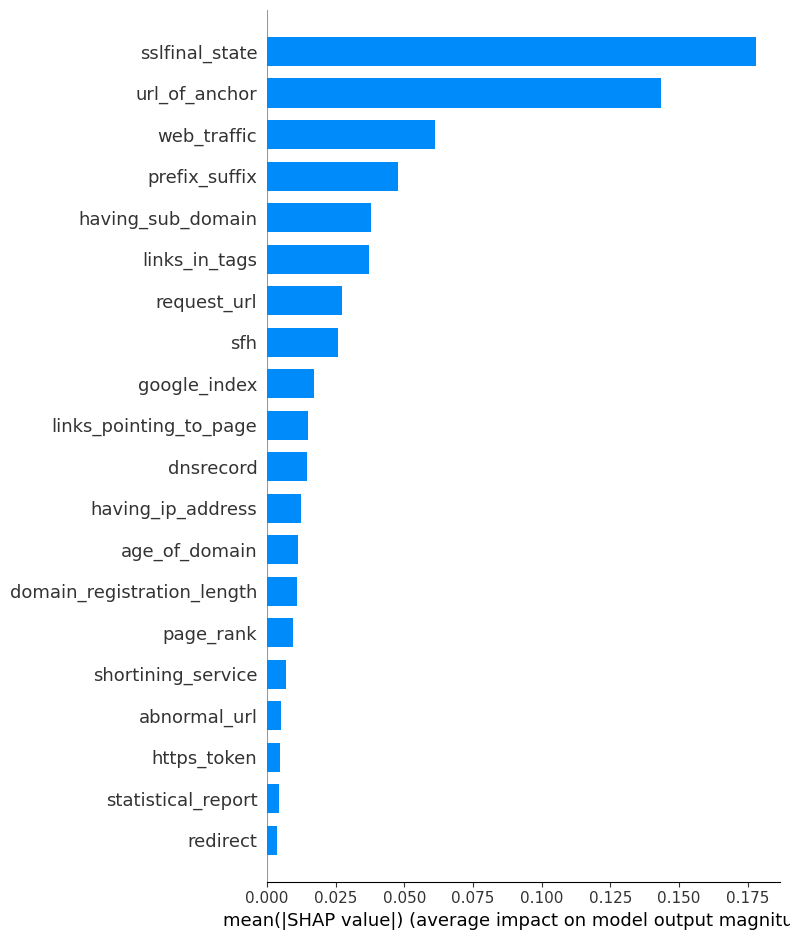

In [14]:
# SHAP global explanations (beeswarm and bar plots) for the phishing class
sample_size = min(250, len(X_test_transformed))
X_shap = X_test_transformed[:sample_size]

explainer = shap.TreeExplainer(tree_estimator)
raw_shap_values = explainer.shap_values(X_shap)

# Support SHAP's common binary-classification output formats
if isinstance(raw_shap_values, list):
    shap_phishing = raw_shap_values[1]
elif np.asarray(raw_shap_values).ndim == 3:
    shap_phishing = np.asarray(raw_shap_values)[:, :, 1]
else:
    shap_phishing = np.asarray(raw_shap_values)

print("SHAP values shape:", np.asarray(shap_phishing).shape)

shap.summary_plot(
    shap_phishing, X_shap,
    feature_names=feature_names,
    show=False
)
plt.tight_layout()
plt.savefig("research_results/shap_summary_beeswarm.png", dpi=300, bbox_inches="tight")
plt.show()

shap.summary_plot(
    shap_phishing, X_shap,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)
plt.tight_layout()
plt.savefig("research_results/shap_global_importance.png", dpi=300, bbox_inches="tight")
plt.show()

## 15. Explain one individual prediction

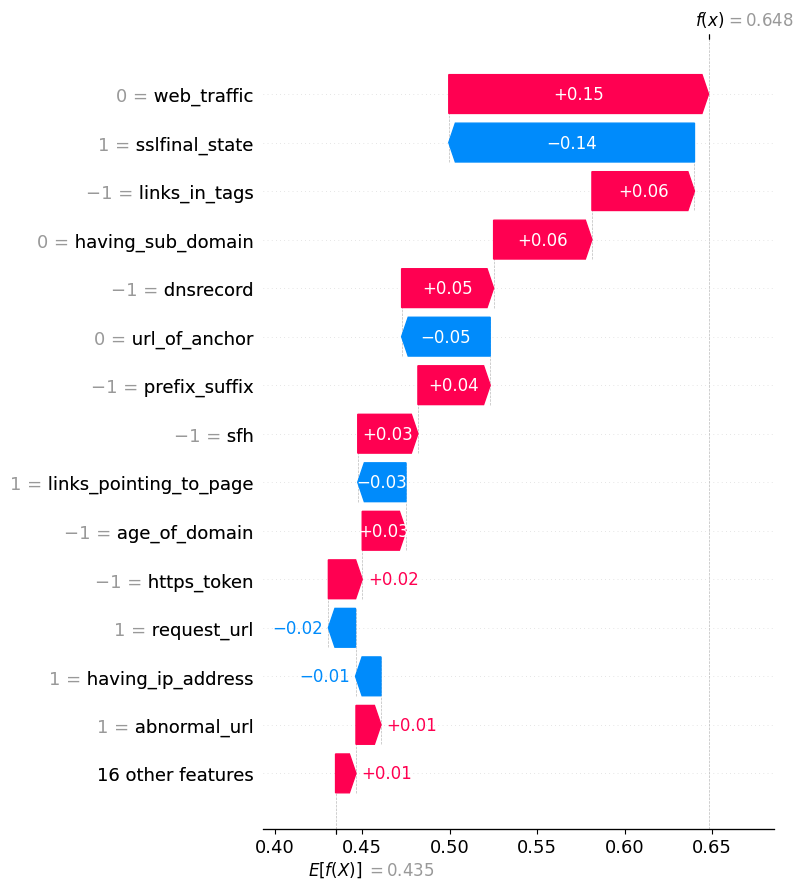

Predicted class: Phishing
Actual class: Phishing


In [15]:
# Explain the first sampled test record
one_row = X_shap[:1]
one_shap = explainer.shap_values(one_row)

if isinstance(one_shap, list):
    one_values = np.asarray(one_shap[1])[0]
    expected = np.asarray(explainer.expected_value)[1]
elif np.asarray(one_shap).ndim == 3:
    one_values = np.asarray(one_shap)[0, :, 1]
    expected = np.asarray(explainer.expected_value)[1]
else:
    one_values = np.asarray(one_shap)[0]
    expected = np.asarray(explainer.expected_value).reshape(-1)[0]

local_exp = shap.Explanation(
    values=one_values,
    base_values=expected,
    data=one_row[0],
    feature_names=feature_names
)
shap.plots.waterfall(local_exp, max_display=15, show=False)
plt.tight_layout()
plt.savefig("research_results/shap_local_waterfall.png", dpi=300, bbox_inches="tight")
plt.show()

first_prediction = best_pipeline.predict(X_test.iloc[:1])[0]
print("Predicted class:", "Phishing" if first_prediction == 1 else "Legitimate")
print("Actual class:", "Phishing" if y_test.iloc[0] == 1 else "Legitimate")

## 16. Permutation feature importance

Permutation importance is measured on the held-out test set. It measures the decrease in F1 after shuffling a feature; it is not a causal explanation.

,Feature,Importance mean,Importance std
13,url_of_anchor,0.10793,0.00467
7,sslfinal_state,0.10482,0.00304
5,prefix_suffix,0.05510,0.00343
25,web_traffic,0.01594,0.00197
14,links_in_tags,0.01236,0.00221
6,having_sub_domain,0.01191,0.00199
23,age_of_domain,0.00892,0.00214
15,sfh,0.00741,0.00153
12,request_url,0.00717,0.00192
27,google_index,0.00616,0.00104


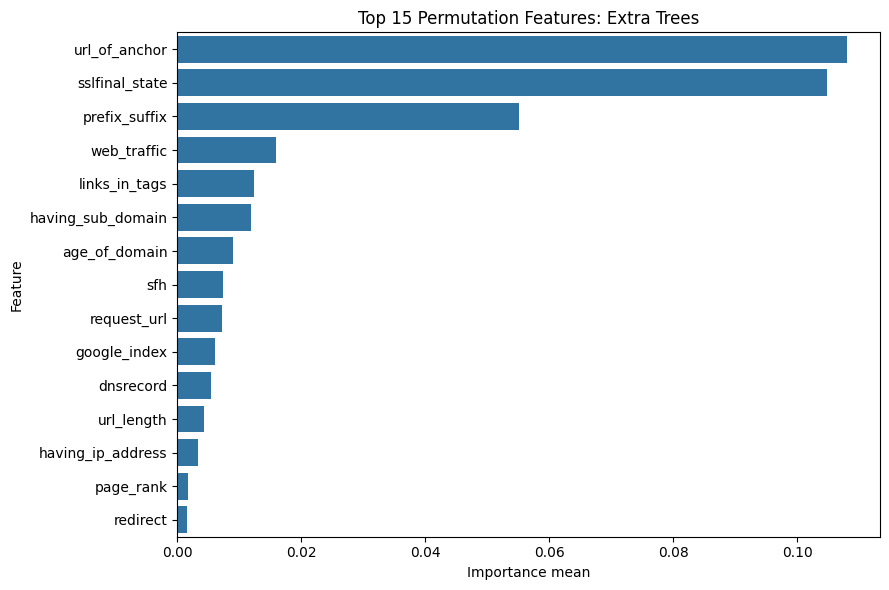

In [16]:
# Permutation importance on the held-out test set (F1 scoring)
perm = permutation_importance(
    best_pipeline, X_test, y_test,
    n_repeats=5, random_state=RANDOM_STATE,
    scoring="f1", n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance mean": perm.importances_mean,
    "Importance std": perm.importances_std
}).sort_values("Importance mean", ascending=False)

display(importance_df.head(20).round(5))
importance_df.to_csv("research_results/permutation_feature_importance.csv", index=False)

plt.figure(figsize=(9, 6))
sns.barplot(data=importance_df.head(15), x="Importance mean", y="Feature")
plt.title(f"Top 15 Permutation Features: {best_tree_name}")
plt.tight_layout()
plt.savefig("research_results/permutation_feature_importance.png", dpi=300)
plt.show()

## 17. Classification reports and predictions

In [17]:
# Per-model classification reports and saved test predictions
for name, (predictions, probabilities) in test_predictions.items():
    print("\n", name)
    print(classification_report(
        y_test, predictions,
        labels=[0, 1],
        target_names=["Legitimate", "Phishing"],
        zero_division=0
    ))

    report = classification_report(
        y_test, predictions,
        labels=[0, 1],
        target_names=["Legitimate", "Phishing"],
        output_dict=True,
        zero_division=0
    )
    pd.DataFrame(report).transpose().to_csv(
        f"research_results/classification_report_{name.replace(' ', '_').lower()}.csv"
    )

prediction_output = pd.DataFrame({
    "actual": y_test.to_numpy(),
    **{f"{name}_predicted": pair[0] for name, pair in test_predictions.items()}
})
prediction_output.to_csv("research_results/test_predictions.csv", index=False)


 Logistic Regression
              precision    recall  f1-score   support

  Legitimate       0.93      0.95      0.94      1128
    Phishing       0.94      0.92      0.93      1029

    accuracy                           0.94      2157
   macro avg       0.94      0.93      0.94      2157
weighted avg       0.94      0.94      0.94      2157


 Decision Tree
              precision    recall  f1-score   support

  Legitimate       0.91      0.95      0.93      1128
    Phishing       0.95      0.89      0.92      1029

    accuracy                           0.93      2157
   macro avg       0.93      0.92      0.92      2157
weighted avg       0.93      0.93      0.93      2157


 Random Forest
              precision    recall  f1-score   support

  Legitimate       0.96      0.96      0.96      1128
    Phishing       0.96      0.95      0.95      1029

    accuracy                           0.96      2157
   macro avg       0.96      0.96      0.96      2157
weighted avg       0

## 18. Statistical uncertainty: stratified bootstrap confidence intervals

A single train/test split gives point estimates. The following stratified bootstrap estimates uncertainty on the fixed held-out test set. These intervals quantify test-sample uncertainty conditional on this split; they do not account for dataset shift or repeated model selection.

In [18]:
# Stratified bootstrap confidence intervals (row-level)
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score
from scipy.stats import binomtest
from statsmodels.stats.multitest import multipletests

BOOTSTRAP_REPS = 2000
rng = np.random.default_rng(RANDOM_STATE)
class0 = np.flatnonzero(y_test.to_numpy() == 0)
class1 = np.flatnonzero(y_test.to_numpy() == 1)

bootstrap_rows = []
for name, (pred, prob) in test_predictions.items():
    vals = {"F1": [], "ROC-AUC": [], "PR-AUC": []}
    for _ in range(BOOTSTRAP_REPS):
        idx = np.concatenate([
            rng.choice(class0, size=len(class0), replace=True),
            rng.choice(class1, size=len(class1), replace=True)
        ])
        yt = y_test.to_numpy()[idx]
        pp = pred[idx]
        pr = prob[idx]
        vals["F1"].append(f1_score(yt, pp, zero_division=0))
        vals["ROC-AUC"].append(roc_auc_score(yt, pr))
        vals["PR-AUC"].append(average_precision_score(yt, pr))
    row = {"Model": name}
    for metric, samples in vals.items():
        row[f"{metric} lower 95%"] = np.percentile(samples, 2.5)
        row[f"{metric} upper 95%"] = np.percentile(samples, 97.5)
    bootstrap_rows.append(row)

bootstrap_df = pd.DataFrame(bootstrap_rows)
display(bootstrap_df.round(4))
bootstrap_df.to_csv("research_results/bootstrap_confidence_intervals.csv", index=False)


,Model,F1 lower 95%,F1 upper 95%,ROC-AUC lower 95%,ROC-AUC upper 95%,PR-AUC lower 95%,PR-AUC upper 95%
0,Logistic Regression,0.9201,0.9427,0.9783,0.9871,0.9796,0.9874
1,Decision Tree,0.9072,0.9311,0.9454,0.9625,0.9181,0.9449
2,Random Forest,0.9456,0.9631,0.9894,0.9945,0.9900,0.9945
3,Extra Trees,0.9478,0.9655,0.9903,0.9951,0.9908,0.9951


## 19. Paired model comparison with McNemar's test

McNemar's test compares paired classification errors on the same test observations. The p-values below are adjusted using the Holm procedure across pairwise model comparisons. Statistical significance does not establish practical superiority; report effect sizes and metric differences alongside p-values.

In [19]:
# Pairwise McNemar exact tests with Holm correction
from itertools import combinations

comparison_rows = []
model_names = list(test_predictions.keys())
for a, b in combinations(model_names, 2):
    pred_a = test_predictions[a][0]
    pred_b = test_predictions[b][0]
    correct_a = pred_a == y_test.to_numpy()
    correct_b = pred_b == y_test.to_numpy()
    n01 = int(np.sum(correct_a & ~correct_b))  # A correct, B wrong
    n10 = int(np.sum(~correct_a & correct_b))  # A wrong, B correct
    discordant = n01 + n10
    p_value = binomtest(min(n01, n10), n=discordant, p=0.5, alternative="two-sided").pvalue if discordant else 1.0
    comparison_rows.append({"Model A": a, "Model B": b, "A correct/B wrong": n01,
                            "A wrong/B correct": n10, "McNemar exact p": p_value})

if comparison_rows:
    pairwise_df = pd.DataFrame(comparison_rows)
    pairwise_df["Holm-adjusted p"] = multipletests(pairwise_df["McNemar exact p"], method="holm")[1]
    display(pairwise_df.round(5))
    pairwise_df.to_csv("research_results/mcnemar_pairwise_comparisons.csv", index=False)
else:
    print("At least two models are required for paired comparisons.")


,Model A,Model B,A correct/B wrong,A wrong/B correct,McNemar exact p,Holm-adjusted p
0,Logistic Regression,Decision Tree,102,80,0.11932,0.23864
1,Logistic Regression,Random Forest,41,87,0.00006,0.00018
2,Logistic Regression,Extra Trees,40,90,0.00001,0.00005
3,Decision Tree,Random Forest,29,97,0.00000,0.00000
4,Decision Tree,Extra Trees,33,105,0.00000,0.00000
5,Random Forest,Extra Trees,7,11,0.48068,0.48068


## 20. Probability calibration and operational threshold analysis

A high ROC-AUC does not guarantee well-calibrated probabilities. Brier score and calibration curves assess probability quality. The default 0.50 threshold is retained for the main comparison; threshold selection for deployment must be based on training/validation data and a documented operational cost function, never optimized on the final test set.

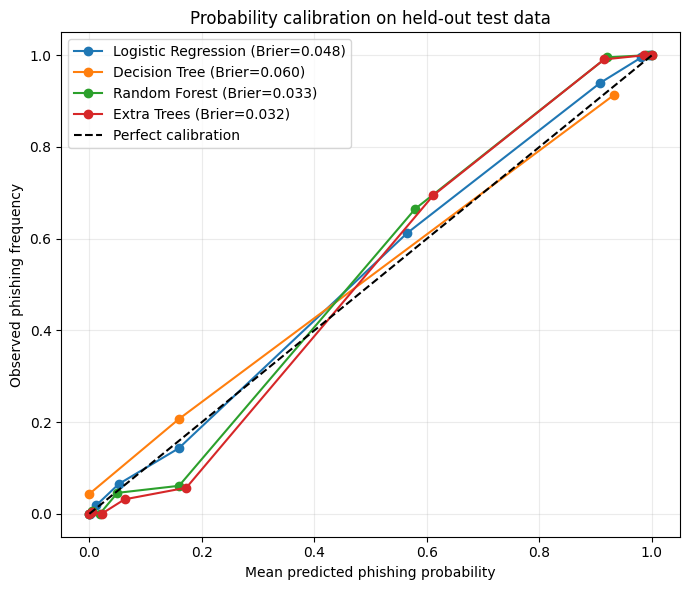

,Model,Brier score
0,Logistic Regression,0.0481
1,Decision Tree,0.0595
2,Random Forest,0.0334
3,Extra Trees,0.0319


In [20]:
# Brier score and calibration curves
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

calibration_rows = []
plt.figure(figsize=(7, 6))
for name, (pred, prob) in test_predictions.items():
    brier = brier_score_loss(y_test, prob)
    fraction_positive, mean_predicted = calibration_curve(
        y_test, prob, n_bins=10, strategy="quantile"
    )
    calibration_rows.append({"Model": name, "Brier score": brier})
    plt.plot(mean_predicted, fraction_positive, marker="o", label=f"{name} (Brier={brier:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
plt.xlabel("Mean predicted phishing probability")
plt.ylabel("Observed phishing frequency")
plt.title("Probability calibration on held-out test data")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("research_results/calibration_curves.png", dpi=300)
plt.show()

calibration_df = pd.DataFrame(calibration_rows)
display(calibration_df.round(4))
calibration_df.to_csv("research_results/calibration_metrics.csv", index=False)


## 21. Repeat inference timing and report hardware context

Single-run timing is noisy. This cell repeats prediction on the same held-out batch. It reports batch latency and per-record latency; these are environment-specific and should not be generalized to production hardware.

In [21]:
# Repeated inference-time measurement
timing_rows = []
for name, model in trained_models.items():
    durations = []
    for _ in range(15):
        start = time.perf_counter()
        _ = model.predict_proba(X_test)
        durations.append(time.perf_counter() - start)
    timing_rows.append({
        "Model": name,
        "Batch latency median (ms)": 1000 * np.median(durations),
        "Batch latency IQR (ms)": 1000 * (np.percentile(durations, 75) - np.percentile(durations, 25)),
        "Median latency (ms/sample)": 1000 * np.median(durations) / len(X_test)
    })
timing_df = pd.DataFrame(timing_rows)
display(timing_df.round(4))
timing_df.to_csv("research_results/repeated_inference_timing.csv", index=False)
print("CPU/platform:", platform.platform())
print("Logical CPU count:", os.cpu_count())


,Model,Batch latency median (ms),Batch latency IQR (ms),Median latency (ms/sample)
0,Logistic Regression,2.6018,0.1689,0.0012
1,Decision Tree,2.2711,0.1143,0.0011
2,Random Forest,61.0939,10.1297,0.0283
3,Extra Trees,68.4709,1.3352,0.0317


CPU/platform: Linux-6.6.159+-x86_64-with-glibc2.39
Logical CPU count: 2


## 22. External validation scope

Sections 1-21 evaluate a single UCI benchmark dataset, so they should not be described as external validation. Independent, cross-source evaluation is performed separately in **Section 25** (PhreshPhish URL-only transfer test) and extended in **Section 41**.

When extending this work with another external dataset, make sure it provides:
- documented collection dates and source provenance;
- verified phishing and benign labels with a defensible labeling policy;
- raw URL/domain data and a reproducible feature-extraction pipeline;
- a time-based or source/campaign-based holdout where feasible;
- deduplication between training and external test data;
- identical feature definitions, missing-value handling, and label semantics.

If the external dataset does not share the same feature schema, do not force a comparison. Build a common feature pipeline from raw URLs or limit the claim to the original benchmark.

## 23. Reporting guidelines

When reporting results from this notebook:
1. Report group-aware cross-validation results and untouched test-set metrics together with confidence intervals, calibration, and paired comparisons.
2. Describe the duplicate-feature audit and the conflicting-label groups.
3. Choose an operating threshold on training or validation data using a documented cost function; never tune it on the test set.
4. Treat SHAP and permutation importance as associational, not causal.
5. Include the computational environment, package versions, random seeds, and run-time variability.
6. State the age and representativeness of the UCI benchmark; do not imply coverage of modern threats.
7. Avoid claims of deployment readiness, real-time protection, cross-domain robustness, or superiority unless directly tested.
8. Report all experiments, including negative results.

## 24. Hyperparameter optimization and expanded baselines

This section tunes the existing model families using only the training partition. Search uses group-aware cross-validation and average precision as the primary selection metric (useful when class prevalence changes). The untouched internal test partition is not used to choose parameters. Search is intentionally bounded for Colab Free; increase `N_ITER` only after checking runtime. A simple DummyClassifier reference is included so gains over a non-informative baseline are visible.

**Comparison with published results:** Published scores from different datasets, feature spaces, sampling procedures, and test protocols are contextual evidence only. They must not be placed in the same leaderboard as results from this notebook unless the benchmark, split, and metric definitions are genuinely comparable.

In [22]:
# Hyperparameter optimization (randomized search) and expanded baselines
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from scipy.stats import randint, loguniform

N_ITER = 8  # Random-search candidates per model (CPU-friendly default; report this budget with results)
TUNE_CV = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)

# Add two widely used nonlinear boosting baselines, using the same input features and folds.
boosting_baselines = {
    "Hist Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE))
    ]),
    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))
    ])
}
models_for_tuning = {**models, **boosting_baselines}

search_spaces = {
    "Logistic Regression": {
        "model__C": loguniform(1e-3, 1e2),
        "model__class_weight": [None, "balanced"]
    },
    "Decision Tree": {
        "model__max_depth": [None, 5, 8, 12, 16, 24, 32],
        "model__min_samples_split": randint(2, 20),
        "model__min_samples_leaf": randint(1, 10),
        "model__class_weight": [None, "balanced"]
    },
    "Random Forest": {
        "model__n_estimators": [150, 250, 350],
        "model__max_depth": [None, 10, 16, 24, 32],
        "model__min_samples_leaf": randint(1, 6),
        "model__max_features": ["sqrt", "log2", 0.7],
        "model__class_weight": [None, "balanced_subsample"]
    },
    "Extra Trees": {
        "model__n_estimators": [150, 250, 350],
        "model__max_depth": [None, 10, 16, 24, 32],
        "model__min_samples_leaf": randint(1, 6),
        "model__max_features": ["sqrt", "log2", 0.7],
        "model__class_weight": [None, "balanced"]
    },
    "Hist Gradient Boosting": {
        "model__learning_rate": loguniform(0.02, 0.2),
        "model__max_iter": [100, 150, 250],
        "model__max_leaf_nodes": [15, 31, 63],
        "model__l2_regularization": loguniform(1e-4, 1.0)
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 150, 250],
        "model__learning_rate": loguniform(0.02, 0.2),
        "model__max_depth": [1, 2, 3],
        "model__min_samples_leaf": randint(1, 8)
    }
}

optimized_models = {}
optimization_rows = []
for model_name, distribution in search_spaces.items():
    print(f"Optimizing {model_name} ({N_ITER} candidates; 4 group-aware folds)")
    search = RandomizedSearchCV(
        estimator=models_for_tuning[model_name], param_distributions=distribution,
        n_iter=N_ITER, scoring="average_precision", cv=TUNE_CV,
        random_state=RANDOM_STATE, n_jobs=-1, refit=True,
        return_train_score=False, verbose=0
    )
    start = time.perf_counter()
    search.fit(X_train, y_train, groups=groups_train)
    elapsed = time.perf_counter() - start
    optimized_models[model_name] = search.best_estimator_
    optimization_rows.append({
        "Model": model_name, "Best CV average precision": search.best_score_,
        "Search seconds": elapsed, "Candidates": N_ITER,
        "Best parameters": str(search.best_params_)
    })
    print("Best AP:", round(search.best_score_, 4), "elapsed:", round(elapsed, 1), "s")

optimization_df = pd.DataFrame(optimization_rows)
display(optimization_df)
optimization_df.to_csv("research_results/hyperparameter_optimization.csv", index=False)

# Evaluate optimized estimators once on the untouched internal test partition.
optimized_test_rows = []
optimized_test_predictions = {}
for model_name, estimator in optimized_models.items():
    start = time.perf_counter(); estimator.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    pred = estimator.predict(X_test)
    prob = estimator.predict_proba(X_test)[:, 1]
    optimized_test_predictions[model_name] = (pred, prob)
    optimized_test_rows.append({
        "Model": model_name, "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC": average_precision_score(y_test, prob),
        "MCC": matthews_corrcoef(y_test, pred), "Fit seconds": fit_seconds
    })
optimized_test_df = pd.DataFrame(optimized_test_rows).sort_values("PR-AUC", ascending=False)
display(optimized_test_df.round(4))
optimized_test_df.to_csv("research_results/optimized_model_test_comparison.csv", index=False)

# A dummy reference on the same held-out test set; no tuning is performed.
dummy = DummyClassifier(strategy="prior")
dummy.fit(X_train, y_train)
dummy_prob = dummy.predict_proba(X_test)[:, 1]
dummy_pred = dummy.predict(X_test)
dummy_row = {"Model":"Dummy prior", "Accuracy":accuracy_score(y_test,dummy_pred),
             "Precision":precision_score(y_test,dummy_pred,zero_division=0),
             "Recall":recall_score(y_test,dummy_pred,zero_division=0),
             "F1":f1_score(y_test,dummy_pred,zero_division=0),
             "ROC-AUC":roc_auc_score(y_test,dummy_prob),
             "PR-AUC":average_precision_score(y_test,dummy_prob),
             "MCC":matthews_corrcoef(y_test,dummy_pred), "Fit seconds":np.nan}
optimized_test_df = pd.concat([optimized_test_df, pd.DataFrame([dummy_row])], ignore_index=True)
optimized_test_df.to_csv("research_results/optimized_model_test_comparison_with_dummy.csv", index=False)
display(optimized_test_df.round(4))

Optimizing Logistic Regression (8 candidates; 4 group-aware folds)
Best AP: 0.9732 elapsed: 2.5 s
Optimizing Decision Tree (8 candidates; 4 group-aware folds)
Best AP: 0.9647 elapsed: 3.9 s
Optimizing Random Forest (8 candidates; 4 group-aware folds)
Best AP: 0.988 elapsed: 57.6 s
Optimizing Extra Trees (8 candidates; 4 group-aware folds)
Best AP: 0.9887 elapsed: 63.5 s
Optimizing Hist Gradient Boosting (8 candidates; 4 group-aware folds)
Best AP: 0.9898 elapsed: 35.8 s
Optimizing Gradient Boosting (8 candidates; 4 group-aware folds)
Best AP: 0.9864 elapsed: 28.6 s


,Model,Best CV average precision,Search seconds,Candidates,Best parameters
0,Logistic Regression,0.973222,2.522245,8,"{'model__C': np.float64(0.9846738873614566), '..."
1,Decision Tree,0.964722,3.947412,8,"{'model__class_weight': 'balanced', 'model__ma..."
2,Random Forest,0.987984,57.553554,8,"{'model__class_weight': 'balanced_subsample', ..."
3,Extra Trees,0.988748,63.458926,8,"{'model__class_weight': 'balanced', 'model__ma..."
4,Hist Gradient Boosting,0.989810,35.779215,8,{'model__l2_regularization': np.float64(0.0244...
5,Gradient Boosting,0.986399,28.645540,8,{'model__learning_rate': np.float64(0.18661212...


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,MCC,Fit seconds
4,Hist Gradient Boosting,0.9583,0.9563,0.9563,0.9563,0.9943,0.9941,0.9164,2.1773
3,Extra Trees,0.9587,0.9502,0.9640,0.9571,0.9924,0.9927,0.9174,0.8677
2,Random Forest,0.9592,0.9564,0.9582,0.9573,0.9917,0.9920,0.9182,1.5181
5,Gradient Boosting,0.9536,0.9668,0.9349,0.9506,0.9913,0.9911,0.9074,1.2015
1,Decision Tree,0.9328,0.9139,0.9485,0.9309,0.9866,0.9854,0.8661,0.0838
0,Logistic Regression,0.9356,0.9441,0.9193,0.9316,0.9829,0.9836,0.8710,0.1221


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,MCC,Fit seconds
0,Hist Gradient Boosting,0.9583,0.9563,0.9563,0.9563,0.9943,0.9941,0.9164,2.1773
1,Extra Trees,0.9587,0.9502,0.9640,0.9571,0.9924,0.9927,0.9174,0.8677
2,Random Forest,0.9592,0.9564,0.9582,0.9573,0.9917,0.9920,0.9182,1.5181
3,Gradient Boosting,0.9536,0.9668,0.9349,0.9506,0.9913,0.9911,0.9074,1.2015
4,Decision Tree,0.9328,0.9139,0.9485,0.9309,0.9866,0.9854,0.8661,0.0838
5,Logistic Regression,0.9356,0.9441,0.9193,0.9316,0.9829,0.9836,0.8710,0.1221
6,Dummy prior,0.5229,0.0000,0.0000,0.0000,0.5000,0.4771,0.0000,NaN


## 25. Contemporary independent validation: PhreshPhish URL-only transfer test

**Dataset choice:** PhreshPhish is a recent real-world phishing/benign URL–HTML benchmark with a pre-defined train/test split and collection dates. Its full release is large (the dataset card reports approximately 36.6 GB), so this notebook streams only a bounded sample from its `test` split and uses the URL field only. This is suitable for a CPU feasibility experiment, not a substitute for the full benchmark protocol. See the dataset card and paper for details.

**Feature compatibility safeguard:** the UCI benchmark contains 30 engineered features, many of which require page content, TLS, DNS, registration, or traffic information. Those features cannot be inferred honestly from a URL string. The external-transfer experiment therefore uses a small, explicitly harmonized URL-only subset (IP address, URL length, shortening service, `@`, redirect marker, domain hyphen, subdomain count, and HTTPS token). The model is retrained on the corresponding UCI columns only, then tested on PhreshPhish URLs. This is a distinct experiment from the 30-feature benchmark; its results should be reported separately, together with the operationalized thresholds below.

The dataset card describes benign/phish labels, URL and HTML fields, date metadata, and a CC BY 4.0 license for anti-phishing research. Verify the current terms and cite the dataset paper when using it.

In [23]:
# Install Hugging Face datasets if needed (CPU only; streamed access avoids downloading all 36.6 GB).
%pip -q install datasets

In [24]:
# Stream a bounded PhreshPhish test sample (seeded reservoir sample)
from datasets import load_dataset
from urllib.parse import urlparse
import ipaddress, re, math, random

# A bounded, seeded reservoir sample from the official test split.
# Set to 10,000 initially for Colab Free; increase after measuring memory/runtime.
EXTERNAL_SAMPLE_N = 10000
external_stream = load_dataset("phreshphish/phreshphish", split="test", streaming=True)
rng_external = random.Random(RANDOM_STATE)
reservoir = []
eligible_seen = 0
for seen, row in enumerate(external_stream, start=1):
    label = str(row.get("label", "")).strip().lower()
    url = row.get("url")
    date = row.get("date")
    if not url or label not in {"phish", "phishing", "benign", "legitimate"}:
        continue
    eligible_seen += 1
    item = {"url": str(url), "label": 1 if label in {"phish", "phishing"} else 0, "date": str(date)}
    if len(reservoir) < EXTERNAL_SAMPLE_N:
        reservoir.append(item)
    else:
        j = rng_external.randrange(eligible_seen)
        if j < EXTERNAL_SAMPLE_N:
            reservoir[j] = item
    if seen % 50000 == 0:
        print("Streamed rows:", seen, "eligible sample:", len(reservoir))

external_raw = pd.DataFrame(reservoir).drop_duplicates(subset=["url"]).reset_index(drop=True)
print("Independent URL records:", len(external_raw))
print("Label counts (0=benign, 1=phish):")
display(external_raw.label.value_counts())
print("Date range in sampled rows:", external_raw.date.min(), "to", external_raw.date.max())
if external_raw.label.nunique() != 2:
    raise ValueError("External sample must contain both classes. Increase sample size or inspect the split labels.")

README.md:   0%|          | 0.00/4.28k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

Streamed rows: 50000 eligible sample: 10000
Streamed rows: 100000 eligible sample: 10000
Streamed rows: 150000 eligible sample: 10000
Independent URL records: 10000
Label counts (0=benign, 1=phish):


,count
label,
0,5445
1,4555


Date range in sampled rows: 2025-09-08 to 2025-12-16


In [25]:
# Explicit URL-only feature extraction, using the UCI creators' coding:
# Legitimate = +1, Suspicious = 0, Phishing = -1 (-1 = phishing condition present).
# A leading 'www.' is stripped before counting subdomain dots.
SHORTENERS = {
    "bit.ly", "tinyurl.com", "goo.gl", "t.co", "ow.ly", "is.gd", "buff.ly",
    "adf.ly", "bit.do", "cutt.ly", "rebrand.ly", "tiny.cc", "lnkd.in"
}

def extract_harmonized_url_features(url):
    raw = str(url).strip()
    candidate = raw if re.match(r"^[a-zA-Z][a-zA-Z0-9+.-]*://", raw) else "http://" + raw
    parsed = urlparse(candidate)
    host = (parsed.hostname or "").lower().strip(".")
    path = parsed.path or ""
    try:
        ipaddress.ip_address(host.strip("[]")); has_ip = -1
    except Exception:
        has_ip = 1
    # UCI URL length uses three bins; these cut-points are predeclared.
    length = len(raw)
    length_bin = 1 if length < 54 else (0 if length <= 75 else -1)
    try:
        domain_parts = host.split(".") if host else []
        domain_core = ".".join(domain_parts[-2:]) if len(domain_parts) >= 2 else host
        shortening = -1 if host in SHORTENERS else 1
        at_symbol = -1 if "@" in raw else 1
        # A second // after the scheme/authority is treated as redirect marker.
        after_scheme = raw.split("://", 1)[-1]
        double_slash = -1 if "//" in after_scheme else 1
        prefix_suffix = -1 if "-" in host else 1
        # Subdomain count strips a leading 'www.' (creators' convention).
        host_core = host[4:] if host.startswith("www.") else host
        core_parts = host_core.split(".") if host_core else []
        dot_count = max(0, len(core_parts) - 1)
        subdomain = 1 if dot_count <= 1 else (0 if dot_count == 2 else -1)
        https_token = -1 if "https" in host else 1
    except Exception:
        shortening, at_symbol, double_slash, prefix_suffix, subdomain, https_token = 1, 1, 1, 1, 1, 1
    return {
        "having_ip_address": has_ip,
        "url_length": length_bin,
        "shortining_service": shortening,
        "having_at_symbol": at_symbol,
        "double_slash_redirecting": double_slash,
        "prefix_suffix": prefix_suffix,
        "having_sub_domain": subdomain,
        "https_token": https_token
    }

URL_FEATURES = [
    "having_ip_address", "url_length", "shortining_service", "having_at_symbol",
    "double_slash_redirecting", "prefix_suffix", "having_sub_domain", "https_token"
]
missing = [c for c in URL_FEATURES if c not in X.columns]
if missing:
    raise ValueError(f"UCI feature names do not match expected harmonized subset: {missing}. Inspect dataset schema.")

X_ext = pd.DataFrame([extract_harmonized_url_features(u) for u in external_raw.url], columns=URL_FEATURES)
y_ext = external_raw.label.astype(int).reset_index(drop=True)

# Train only on the same eight URL-derived features; no UCI page/DNS/age/traffic features leak into this test.
url_only_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", ExtraTreesClassifier(n_estimators=250, max_features="sqrt", class_weight="balanced",
                                   random_state=RANDOM_STATE, n_jobs=-1))
])
url_only_model.fit(X_train[URL_FEATURES], y_train)
ext_pred = url_only_model.predict(X_ext)
ext_prob = url_only_model.predict_proba(X_ext)[:, 1]
external_metrics = {
    "Dataset": "PhreshPhish test split (streamed URL-only sample)",
    "N": len(y_ext), "Phishing prevalence": float(y_ext.mean()),
    "Accuracy": accuracy_score(y_ext, ext_pred),
    "Precision": precision_score(y_ext, ext_pred, zero_division=0),
    "Recall": recall_score(y_ext, ext_pred, zero_division=0),
    "F1": f1_score(y_ext, ext_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_ext, ext_prob),
    "PR-AUC": average_precision_score(y_ext, ext_prob),
    "MCC": matthews_corrcoef(y_ext, ext_pred)
}
external_metrics_df = pd.DataFrame([external_metrics])
display(external_metrics_df.round(4))
external_metrics_df.to_csv("research_results/phreshphish_external_validation_metrics.csv", index=False)
pd.DataFrame({"url": external_raw.url, "date": external_raw.date, "actual": y_ext,
              "predicted": ext_pred, "phishing_probability": ext_prob}).to_csv(
    "research_results/phreshphish_external_predictions.csv", index=False)
print(classification_report(y_ext, ext_pred, target_names=["Benign", "Phishing"], zero_division=0))

,Dataset,N,Phishing prevalence,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,MCC
0,PhreshPhish test split (streamed URL-only sample),10000,0.4555,0.4351,0.4113,0.557,0.4732,0.4744,0.4514,-0.1126


              precision    recall  f1-score   support

      Benign       0.47      0.33      0.39      5445
    Phishing       0.41      0.56      0.47      4555

    accuracy                           0.44     10000
   macro avg       0.44      0.45      0.43     10000
weighted avg       0.45      0.44      0.43     10000



### External feature-mapping sensitivity analysis

The URL-length and subdomain cut-points are operational choices. This cell checks whether external performance is highly dependent on nearby URL-length thresholds. The model remains trained on the fixed UCI feature encoding; only the external feature extraction thresholds are varied. Treat this as a sensitivity check, not a re-optimized result.

In [26]:
# Vary the URL-length cut-points used for the external feature mapping
def extract_url_features_with_thresholds(url, short_cut=54, long_cut=75):
    feats = extract_harmonized_url_features(url)
    raw = str(url).strip()
    L = len(raw)
    feats["url_length"] = 1 if L < short_cut else (0 if L <= long_cut else -1)
    return feats

sensitivity_rows = []
for short_cut, long_cut in [(50, 70), (54, 75), (60, 80)]:
    X_ext_sens = pd.DataFrame(
        [extract_url_features_with_thresholds(u, short_cut, long_cut) for u in external_raw.url],
        columns=URL_FEATURES
    )
    p_sens = url_only_model.predict(X_ext_sens)
    pr_sens = url_only_model.predict_proba(X_ext_sens)[:, 1]
    sensitivity_rows.append({
        "Short/medium cut": short_cut, "Medium/long cut": long_cut,
        "Accuracy": accuracy_score(y_ext, p_sens),
        "F1": f1_score(y_ext, p_sens, zero_division=0),
        "ROC-AUC": roc_auc_score(y_ext, pr_sens),
        "PR-AUC": average_precision_score(y_ext, pr_sens),
        "MCC": matthews_corrcoef(y_ext, p_sens)
    })
external_sensitivity_df = pd.DataFrame(sensitivity_rows)
display(external_sensitivity_df.round(4))
external_sensitivity_df.to_csv("research_results/external_feature_threshold_sensitivity.csv", index=False)


,Short/medium cut,Medium/long cut,Accuracy,F1,ROC-AUC,PR-AUC,MCC
0,50,70,0.4399,0.4729,0.4780,0.4559,-0.1039
1,54,75,0.4351,0.4732,0.4744,0.4514,-0.1126
2,60,80,0.4193,0.4704,0.4561,0.4421,-0.1426


### External validation interpretation and limits

- This is an independent-source, URL-only transfer test: UCI-trained URL-feature model → PhreshPhish test URLs.
- It is **not** a 30-feature transfer test. Do not compare its score directly with the 30-feature UCI model score.
- URL lexical feature thresholds are operational definitions. Validate them against the UCI feature documentation and run a sensitivity analysis (above) before relying on the results.
- The PhreshPhish test split is not necessarily a purely future-only test relative to every UCI record; describe the actual date distribution sampled above. Do not call it strict temporal validation unless the time ordering and cut-off are verified.
- Dataset source labels and URL strings should be treated as supplied labels, not as independent ground-truth verification by this notebook. Discuss label provenance and possible stale/inaccessible URLs.
- If streaming fails because of network, library, or dataset-card changes, stop and use the official release instructions; do not silently substitute another dataset.

## 26. Explainability stability across data folds

A high-impact interpretability claim should establish whether the explanation is reproducible under reasonable changes in the training sample. This section fits the same Extra Trees family on each group-aware training fold, computes mean absolute SHAP values on a fixed reference sample, and compares feature rankings using Spearman rank correlation and top-k Jaccard overlap. The fixed reference sample is drawn from the training partition only; the held-out test set is not used to calculate explanation stability.

Stability is a property of this model, dataset, feature representation, and sampling protocol. It does not establish causal importance or human interpretability by itself.

Fold 1: SHAP importance calculated
Fold 2: SHAP importance calculated
Fold 3: SHAP importance calculated
Fold 4: SHAP importance calculated
Fold 5: SHAP importance calculated


,Fold A,Fold B,Spearman rho,Top-k Jaccard
0,fold_1,fold_2,0.9915,1.0000
1,fold_1,fold_3,0.9889,0.8182
2,fold_1,fold_4,0.9902,0.8182
3,fold_1,fold_5,0.9867,1.0000
4,fold_2,fold_3,0.9893,0.8182
5,fold_2,fold_4,0.9924,0.8182
6,fold_2,fold_5,0.9884,1.0000
7,fold_3,fold_4,0.9947,1.0000
8,fold_3,fold_5,0.9880,0.8182
9,fold_4,fold_5,0.9933,0.8182


,Mean pairwise Spearman rho,SD pairwise Spearman rho,Mean top-k Jaccard,SD top-k Jaccard,Top-k,Reference sample size
0,0.9903,0.0026,0.8909,0.0939,10,300


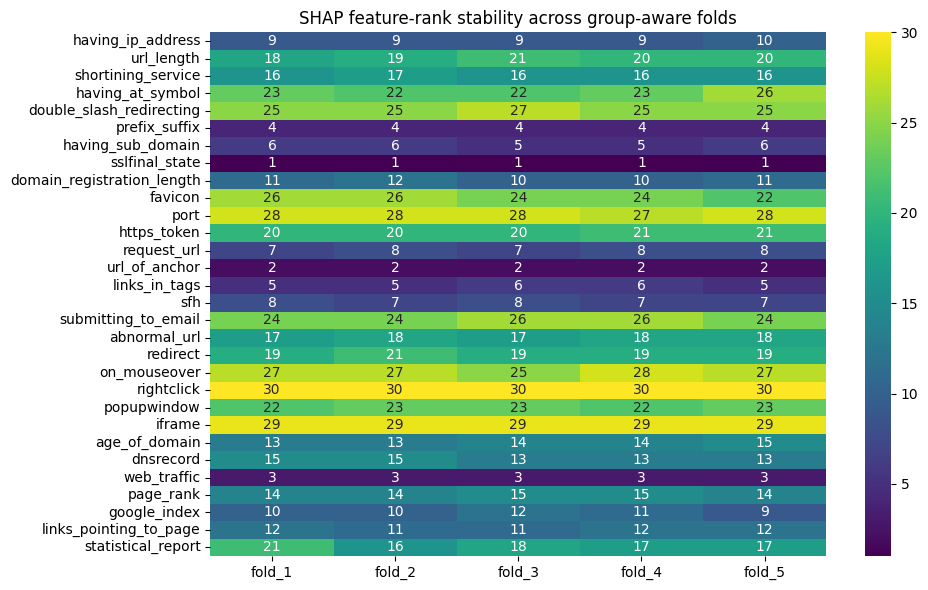

In [27]:
# SHAP explanation stability across group-aware folds (Spearman rho and top-k Jaccard)
from scipy.stats import spearmanr
from itertools import combinations

STABILITY_SAMPLE_N = min(300, len(X_train))
X_stability_ref = X_train.sample(n=STABILITY_SAMPLE_N, random_state=RANDOM_STATE)
fold_importances = []
stability_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for fold_id, (fit_idx, valid_idx) in enumerate(stability_cv.split(X_train, y_train, groups=groups_train), start=1):
    fold_model = ExtraTreesClassifier(
        n_estimators=180, max_features="sqrt", max_depth=24,
        min_samples_leaf=1, class_weight="balanced",
        random_state=RANDOM_STATE + fold_id, n_jobs=-1
    )
    fold_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", fold_model)])
    fold_pipe.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
    ref_transformed = fold_pipe.named_steps["imputer"].transform(X_stability_ref)
    expl = shap.TreeExplainer(fold_pipe.named_steps["model"])
    sv = expl.shap_values(ref_transformed)
    if isinstance(sv, list):
        sv_pos = np.asarray(sv[1])
    else:
        sv_arr = np.asarray(sv)
        sv_pos = sv_arr[:, :, 1] if sv_arr.ndim == 3 else sv_arr
    mean_abs = np.abs(sv_pos).mean(axis=0)
    fold_importances.append(pd.Series(mean_abs, index=X.columns, name=f"fold_{fold_id}"))
    print(f"Fold {fold_id}: SHAP importance calculated")

importance_by_fold = pd.concat(fold_importances, axis=1)
importance_by_fold.to_csv("research_results/shap_importance_by_fold.csv")
rank_by_fold = importance_by_fold.rank(ascending=False, method="average")
rank_corr = []
TOP_K = min(10, X.shape[1])
for a, b in combinations(importance_by_fold.columns, 2):
    rho = spearmanr(rank_by_fold[a], rank_by_fold[b]).statistic
    top_a = set(importance_by_fold[a].nlargest(TOP_K).index)
    top_b = set(importance_by_fold[b].nlargest(TOP_K).index)
    jac = len(top_a & top_b) / len(top_a | top_b)
    rank_corr.append({"Fold A": a, "Fold B": b, "Spearman rho": rho, "Top-k Jaccard": jac})
stability_pairs_df = pd.DataFrame(rank_corr)
display(stability_pairs_df.round(4))
stability_pairs_df.to_csv("research_results/shap_stability_pairwise.csv", index=False)

stability_summary = pd.DataFrame([{
    "Mean pairwise Spearman rho": stability_pairs_df["Spearman rho"].mean(),
    "SD pairwise Spearman rho": stability_pairs_df["Spearman rho"].std(ddof=1),
    "Mean top-k Jaccard": stability_pairs_df["Top-k Jaccard"].mean(),
    "SD top-k Jaccard": stability_pairs_df["Top-k Jaccard"].std(ddof=1),
    "Top-k": TOP_K, "Reference sample size": STABILITY_SAMPLE_N
}])
display(stability_summary.round(4))
stability_summary.to_csv("research_results/shap_stability_summary.csv", index=False)

plt.figure(figsize=(10, 6))
sns.heatmap(rank_by_fold, annot=True, fmt=".0f", cmap="viridis")
plt.title("SHAP feature-rank stability across group-aware folds")
plt.tight_layout(); plt.savefig("research_results/shap_rank_stability_heatmap.png", dpi=300); plt.show()

## 27. Related work, datasets, and research questions

### Datasets and related resources

The sources below are a starting point, not a complete literature review. Verify bibliographic details, dataset versions, and methods in the original publications before citing.

| Work / resource | Relevance to this study | How it is used here |
|---|---|---|
| LegitPhish (2025), manually verified 101,219-URL dataset | Contemporary labelled URL dataset and feature-engineering context | Context for label provenance and lexical feature design |
| PhreshPhish (2025; dataset card updated 2026) | Large-scale real-world URL–HTML pairs with dates and predefined splits | Independent source validation (Sections 25 and 41) |
| Explainable AI for phishing URL detection (Frontiers in AI, 2026) | SHAP, Bayesian optimization, stacking, and statistical validation | Related work on explainable phishing detection |
| UCI Phishing Websites (2015 repository record; 11,055 rows, 30 features) | Historical benchmark | Reference benchmark; limited by dataset age and feature set |

### Research questions

1. How much does predictive performance change when a model trained on a historical engineered-feature benchmark is evaluated on independently collected contemporary URLs using only harmonized URL-level features?
2. Which lightweight model provides the best performance–latency trade-off under group-aware validation and a fixed computational budget?
3. Are the top explanatory features stable across training folds, and do they remain informative under external-source shift?
4. How do false-positive and false-negative rates change under realistic class prevalence and threshold choices?

### Links

- UCI dataset: https://archive.ics.uci.edu/dataset/327/phishing
- PhreshPhish dataset card: https://huggingface.co/datasets/phreshphish/phreshphish
- PhreshPhish paper: https://arxiv.org/abs/2507.10854
- LegitPhish article: https://pmc.ncbi.nlm.nih.gov/articles/PMC12538017/
- Explainable phishing URL study (2026): https://www.frontiersin.org/journals/artificial-intelligence/articles/10.3389/frai.2026.1854934/full

### Comparing with published results

Keep two separate groups of results: (A) baselines reproduced by this notebook under identical splits and metrics, and (B) published results from other studies, which use different datasets, feature spaces, and protocols. Do not rank scores across these groups as if they came from one experiment.

## 29. Export a reproducibility record

The record captures package versions, data dimensions, split settings, random seed, and the selected SHAP model.

In [28]:
# Export a reproducibility record (metadata JSON)
import json

metadata = {
    "dataset": "UCI Phishing Websites (UCI repository ID 327)",
    "target_mapping": {"0": "Legitimate", "1": "Phishing"},
    "records_retained": int(len(X)),
    "unique_feature_vectors": int(groups.nunique()),
    "feature_group_overlap_train_test": int(len(set(groups_train).intersection(set(groups_test)))),
    "number_of_features": int(X.shape[1]),
    "training_records": int(len(X_train)),
    "test_records": int(len(X_test)),
    "test_size": 0.20,
    "random_state": RANDOM_STATE,
    "cross_validation": "5-fold StratifiedGroupKFold",
    "models": list(models.keys()),
    "tuned_models": list(optimized_models.keys()) if "optimized_models" in globals() else [],
    "randomized_search_iterations_per_model": N_ITER if "N_ITER" in globals() else None,
    "external_dataset": "PhreshPhish test split; URL-only sample" if "external_raw" in globals() else "not run",
    "external_sample_n": int(len(external_raw)) if "external_raw" in globals() else None,
    "external_feature_subset": URL_FEATURES if "URL_FEATURES" in globals() else [],
    "mean_shap_rank_spearman": float(stability_summary.iloc[0]["Mean pairwise Spearman rho"]) if "stability_summary" in globals() else None,
    "mean_shap_topk_jaccard": float(stability_summary.iloc[0]["Mean top-k Jaccard"]) if "stability_summary" in globals() else None,
    "shap_model_selected_by_training_cv_f1": best_tree_name,
    "python_version": platform.python_version(),
    "sklearn_version": sklearn.__version__,
    "shap_version": shap.__version__,
    "platform": platform.platform(),
    "cpu_count": os.cpu_count()
}

with open("research_results/experiment_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print(json.dumps(metadata, indent=2))

{
  "dataset": "UCI Phishing Websites (UCI repository ID 327)",
  "target_mapping": {
    "0": "Legitimate",
    "1": "Phishing"
  },
  "records_retained": 11055,
  "unique_feature_vectors": 5785,
  "feature_group_overlap_train_test": 0,
  "number_of_features": 30,
  "training_records": 8898,
  "test_records": 2157,
  "test_size": 0.2,
  "random_state": 42,
  "cross_validation": "5-fold StratifiedGroupKFold",
  "models": [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "Extra Trees"
  ],
  "tuned_models": [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "Extra Trees",
    "Hist Gradient Boosting",
    "Gradient Boosting"
  ],
  "randomized_search_iterations_per_model": 8,
  "external_dataset": "PhreshPhish test split; URL-only sample",
  "external_sample_n": 10000,
  "external_feature_subset": [
    "having_ip_address",
    "url_length",
    "shortining_service",
    "having_at_symbol",
    "double_slash_redirecting",
    "prefix_suff

## 30. Final interpretation checklist

1. Report actual values from the generated CSV files; do not invent or estimate results.
2. State that the main benchmark is a single engineered-feature dataset.
3. Describe the duplicate-feature audit and the group-aware split.
4. Report group-aware CV means and standard deviations, bootstrap intervals, paired tests, calibration, and repeated timing.
5. Discuss practical implications using measured false-positive/false-negative rates and an explicit cost model.
6. Do not claim external, temporal, campaign-level, or deployment generalization beyond what the experiments in Sections 25 and 41 support.

**End of the core experimental workflow.** Sections 31-43 contain the results summary and additional robustness analyses.

## 31. Download all results as a ZIP file

The ZIP contains CSV result tables, plots, classification reports, predictions, and experiment metadata.

In [29]:
# Archive the results folder as a ZIP file
import shutil

shutil.make_archive(
    "phishing_research_results",
    "zip",
    root_dir="research_results"
)

try:
    from google.colab import files
    files.download("phishing_research_results.zip")
except ImportError:
    print("Notebook is not running in Google Colab. ZIP saved in the current directory.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 31a. Summary of reference-run results

The values below were taken from the results archive of a reference run (`phishing_research_results`). They document that run and are not a substitute for rerunning the notebook in a clean runtime; your numbers may differ slightly.

The reference run used 11,055 UCI observations with 30 features, 8,898 training rows, 2,157 test rows, zero feature-group overlap between train and test, five-fold `StratifiedGroupKFold`, and eight randomized-search candidates per model.

| Analysis | Result | Interpretation |
|---|---:|---|
| Unique UCI feature vectors | 5,785 of 11,055 rows | 5,270 rows are additional occurrences of an already-seen feature vector; retained and disclosed rather than silently deduplicated |
| Repeated feature-vector groups | 2,614 | Repeated observations are common, which justifies group-aware splitting |
| Conflicting-label groups | 64 groups (357 rows) | Identical feature vectors carry both labels; see Sections 33 and 37 |
| Group-aware CV F1, Extra Trees | 0.9465 ± 0.0085 | Internal resampling result; not external generalization |
| Tuned internal test F1, Random Forest | 0.9573 | Highest F1 in the tuned comparison, only marginally above Extra Trees (0.9571) |
| Tuned internal test ROC-AUC, Hist Gradient Boosting | 0.9943 | Highest ROC-AUC in the tuned comparison; differs from the highest-F1 model |
| McNemar, Random Forest vs Extra Trees | Holm-adjusted p = 0.4807 | No evidence of a significant paired error difference |
| SHAP rank stability | Mean Spearman rho = 0.9903; top-10 Jaccard = 0.8909 | High rank consistency across the five folds for this model, feature set, and reference sample only |
| PhreshPhish URL-only sample | n = 10,000; phishing prevalence = 45.55% | Convenience reservoir sample, not the dataset's published low-base-rate benchmark protocol |
| PhreshPhish transfer performance | Accuracy = 0.6551; F1 = 0.4143; ROC-AUC = 0.5734; MCC = 0.3616 | Weak but positive transfer; conservative model (high precision, low recall) |

### Interpretation notes and limitations

1. **Model ranking.** The tuned F1 values for Random Forest and Extra Trees are almost identical and the paired comparison is not significant, so no model should be described as statistically superior.
2. **PhreshPhish transfer.** With the corrected UCI coding (Section 25), the eight-feature UCI-trained model transfers weakly but positively: ROC-AUC 0.5734 and MCC 0.3616 on the fixed split (0.574 ± 0.001 and 0.359 ± 0.006 over ten seeds), with high precision (0.9145) but low recall (0.2678). Labels are mapped as `phish` = 1 and `benign` = 0 and must not be reversed to improve metrics. Sections 35 and 41 help separate feature weakness from distribution shift.
3. **Sampled prevalence.** The sample's phishing prevalence is not an operational base rate. PhreshPhish documents dedicated benchmark subsets at low phishing base rates (0.05% to 5%); use them before drawing conclusions about precision, PR-AUC, or alert burden. Section 40 provides prevalence-adjusted estimates.
4. **Approximate feature mapping.** URL-length bins, subdomain counts, shortening-service coverage, and the redirect marker are approximations of the UCI feature definitions. If semantic equivalence cannot be established, treat the experiment as a cross-source feature-transfer pilot rather than strict harmonized validation.
5. **Cluster-aware uncertainty.** The row-level bootstrap intervals (Section 18) and McNemar tests (Section 19) assume independent rows. Because feature vectors repeat, Sections 32 and 38 add cluster-bootstrap intervals and a group-aware paired test, and Sections 33 and 37 analyze the conflicting-label groups.

### External benchmark source

The PhreshPhish dataset card describes `label` values `phish` and `benign`, a predefined test split, collection dates, and benchmark subsets with phishing base rates from 0.05% to 5%. Document the exact release and subset used. Citation: Dalton et al., *PhreshPhish: A Real-World, High-Quality, Large-Scale Phishing Website Dataset and Benchmark* (arXiv:2507.10854, 2025). Dataset: https://huggingface.co/datasets/phreshphish/phreshphish ; paper: https://arxiv.org/abs/2507.10854.

## 32. Cluster-bootstrap confidence intervals for the internal test set

Run this after the split and optimized-model cells. It resamples entire feature-vector groups rather than individual rows, preserving duplicate clusters. This does not resolve conflicting labels; report those separately and repeat the analysis after excluding conflict groups as a sensitivity check.

In [30]:
# Cluster bootstrap: resample complete feature-vector groups on the held-out test set.
# This is preferable to an ordinary row bootstrap when identical feature vectors repeat.
from sklearn.metrics import f1_score, roc_auc_score

rng_cluster = np.random.default_rng(RANDOM_STATE)
test_group_values = np.asarray(groups_test)
unique_test_groups = np.unique(test_group_values)
cluster_to_idx = {g: np.flatnonzero(test_group_values == g) for g in unique_test_groups}
N_CLUSTER_BOOT = 1000
cluster_boot_rows = []

# Use the tuned model predictions generated in Section 24.
for model_name, (pred_all, prob_all) in optimized_test_predictions.items():
    f1_samples, auc_samples = [], []
    for _ in range(N_CLUSTER_BOOT):
        sampled_groups = rng_cluster.choice(unique_test_groups, size=len(unique_test_groups), replace=True)
        idx = np.concatenate([cluster_to_idx[g] for g in sampled_groups])
        y_b = np.asarray(y_test)[idx]
        p_b = np.asarray(pred_all)[idx]
        s_b = np.asarray(prob_all)[idx]
        if np.unique(y_b).size < 2:
            continue
        f1_samples.append(f1_score(y_b, p_b, zero_division=0))
        auc_samples.append(roc_auc_score(y_b, s_b))
    cluster_boot_rows.append({
        "Model": model_name,
        "Cluster-bootstrap F1 lower 95%": np.percentile(f1_samples, 2.5),
        "Cluster-bootstrap F1 upper 95%": np.percentile(f1_samples, 97.5),
        "Cluster-bootstrap ROC-AUC lower 95%": np.percentile(auc_samples, 2.5),
        "Cluster-bootstrap ROC-AUC upper 95%": np.percentile(auc_samples, 97.5),
        "Valid bootstrap replicates": len(f1_samples)
    })

cluster_bootstrap_df = pd.DataFrame(cluster_boot_rows)
display(cluster_bootstrap_df.round(4))
cluster_bootstrap_df.to_csv("research_results/cluster_bootstrap_confidence_intervals.csv", index=False)

,Model,Cluster-bootstrap F1 lower 95%,Cluster-bootstrap F1 upper 95%,Cluster-bootstrap ROC-AUC lower 95%,Cluster-bootstrap ROC-AUC upper 95%,Valid bootstrap replicates
0,Logistic Regression,0.9134,0.9469,0.9758,0.9889,1000
1,Decision Tree,0.9114,0.9488,0.9807,0.9915,1000
2,Random Forest,0.9412,0.9722,0.9866,0.9957,1000
3,Extra Trees,0.9402,0.9712,0.9874,0.9962,1000
4,Hist Gradient Boosting,0.9408,0.9726,0.9906,0.9972,1000
5,Gradient Boosting,0.9329,0.9675,0.9866,0.9951,1000


## 33. Conflicting-label sensitivity analysis

The duplicate audit in the reference run found 64 feature-vector groups (357 rows) containing more than one target label. This is a substantive data-quality issue: identical 30-feature inputs cannot be deterministically separated by a classifier. Where possible, trace these rows to the source data if possible. At minimum, rerun the internal evaluation after excluding all conflicting groups, compare it with the full grouped evaluation, and report both sample sizes and metrics. Do not silently drop these records from the primary analysis.

In [31]:
# Sensitivity analysis: exclude all feature-vector groups with conflicting labels.
conflict_groups = set(audit.groupby("group")["target"].nunique().loc[lambda s: s > 1].index)
keep_mask = ~groups.isin(conflict_groups)
print("Rows in full data:", len(X), "| rows after excluding conflicting groups:", int(keep_mask.sum()))
print("Conflicting groups excluded:", len(conflict_groups))

# This cell reports the filtered dataset size and class balance only.
# The full re-run on the filtered data is performed in Section 37.
X_clean = X.loc[keep_mask].reset_index(drop=True)
y_clean = y.loc[keep_mask].reset_index(drop=True)
groups_clean = groups.loc[keep_mask].reset_index(drop=True)
display(y_clean.value_counts().rename_axis("class").to_frame("count"))

Rows in full data: 11055 | rows after excluding conflicting groups: 10698
Conflicting groups excluded: 64


,count
class,
0,5945
1,4753


# Additional robustness analyses (Sections 34-43)

These cells extend the core workflow with additional robustness checks. **Run them after Section 33**; they reuse `X`, `y`, `groups`, `models`, `optimized_models`, `test_predictions`, `optimized_test_predictions`, `X_ext`, `y_ext`, `external_raw` and `external_metrics_df`. Report only values produced by your own run.

| Analysis | Section |
|---|---|
| Eight-feature UCI baseline (separates feature weakness from distribution shift) | 35, 41 |
| Multiple random seeds (10) and outer-fold sensitivity | 35, 36 |
| Conflicting-label groups: distribution, error floor, and full re-run without them | 37 |
| Group-aware paired test (replaces the row-independence assumption of McNemar) | 38 |
| SHAP stability baselines (decision tree, random forest) | 39 |
| Cost-sensitive threshold and prevalence-adjusted metrics | 40 |
| Modern URL-based baselines and end-to-end latency | 41 |
| Hyperparameter ranges, expanded search, tree-count/depth ablation | 42 |
| Code availability: README and result bundle | 43 |

Approximate runtime on Colab CPU: Sections 35-38 and 40 take a few minutes. Section 39 takes a few minutes. Section 41 streams data from Hugging Face (and uses `torch`, preinstalled on Colab) and can take 10-30 minutes. Section 42 is optional and slow (`EXPANDED_SEARCH = False` by default).

## 34. Shared helpers for the revision analyses

In [32]:
# Shared helpers for the robustness analyses (Sections 34-43)
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict
from itertools import combinations
from scipy.stats import spearmanr, binomtest

REV_DIR = "research_results/revision"
os.makedirs(REV_DIR, exist_ok=True)

SEEDS = [42, 7, 11, 23, 101, 202, 303, 404, 505, 606]   # 10 seeds; report mean and SD

URL8 = ["having_ip_address", "url_length", "shortining_service", "having_at_symbol",
        "double_slash_redirecting", "prefix_suffix", "having_sub_domain", "https_token"]
assert set(URL8) <= set(X.columns), "URL8 feature names do not match the UCI schema."

def holm_adjust(pvals):
    """Holm step-down adjusted p-values (no statsmodels dependency)."""
    p = np.asarray(pvals, dtype=float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    m = len(p)
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj

def group_split(Xd, yd, gd, seed, fold=0, n_splits=5):
    """Group-aware outer split: returns (train_idx, test_idx) for the requested fold."""
    sp = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for k, (tr, te) in enumerate(sp.split(Xd, yd, groups=gd)):
        if k == fold:
            return tr, te
    raise ValueError("fold out of range")

def metric_row(yt, pred, prob):
    yt = np.asarray(yt)
    tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(yt, pred),
        "Precision": precision_score(yt, pred, zero_division=0),
        "Recall": recall_score(yt, pred, zero_division=0),
        "F1": f1_score(yt, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(yt, prob),
        "PR-AUC": average_precision_score(yt, prob),
        "MCC": matthews_corrcoef(yt, pred),
        "FPR": fp / (fp + tn) if (fp + tn) else np.nan,
        "FNR": fn / (fn + tp) if (fn + tp) else np.nan,
    }

def model_specs(seed):
    """Fresh estimators for one seed. Value = (estimator, feature subset or None for all 30)."""
    imp = lambda: SimpleImputer(strategy="median")
    specs = {
        "Logistic Regression": (Pipeline([("imputer", imp()), ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=1500, random_state=seed))]), None),
        "Decision Tree": (Pipeline([("imputer", imp()),
            ("model", DecisionTreeClassifier(max_depth=15, random_state=seed))]), None),
        "Random Forest (baseline)": (Pipeline([("imputer", imp()),
            ("model", RandomForestClassifier(n_estimators=150, max_depth=20, n_jobs=-1, random_state=seed))]), None),
        "Extra Trees (baseline)": (Pipeline([("imputer", imp()),
            ("model", ExtraTreesClassifier(n_estimators=150, max_depth=20, n_jobs=-1, random_state=seed))]), None),
        # Same configuration as the transfer model in Section 25, trained on the 8 URL-derived features only.
        "Extra Trees 8-feature URL-only": (Pipeline([("imputer", imp()),
            ("model", ExtraTreesClassifier(n_estimators=250, max_features="sqrt", class_weight="balanced",
                                           random_state=seed, n_jobs=-1))]), URL8),
    }
    if "optimized_models" in globals():
        for nm in ["Random Forest", "Extra Trees", "Hist Gradient Boosting"]:
            if nm in optimized_models:
                est = clone(optimized_models[nm])
                est.set_params(model__random_state=seed)
                specs[f"{nm} (tuned params)"] = (est, None)
    return specs

def run_multiseed(Xd, yd, gd, tag, seeds=SEEDS, fold=0):
    """Re-run split + fit + test evaluation for every seed. The seed changes BOTH the group split
    and the estimator randomness. Returns one row per (seed, model)."""
    rows = []
    for seed in seeds:
        tr, te = group_split(Xd, yd, gd, seed, fold=fold)
        assert len(set(gd.iloc[tr]) & set(gd.iloc[te])) == 0, "group leakage"
        for name, (est, feats) in model_specs(seed).items():
            cols = feats if feats is not None else list(Xd.columns)
            est.fit(Xd.iloc[tr][cols], yd.iloc[tr])
            pred = est.predict(Xd.iloc[te][cols])
            prob = est.predict_proba(Xd.iloc[te][cols])[:, 1]
            row = {"Dataset": tag, "Seed": seed, "Outer fold": fold, "Model": name,
                   "n_train": len(tr), "n_test": len(te)}
            row.update(metric_row(yd.iloc[te], pred, prob))
            # Transfer of the 8-feature model to PhreshPhish, if the external sample exists.
            if feats is URL8 and "X_ext" in globals():
                pe = est.predict(X_ext[URL8]); se = est.predict_proba(X_ext[URL8])[:, 1]
                row["PhreshPhish ROC-AUC"] = roc_auc_score(y_ext, se)
                row["PhreshPhish MCC"] = matthews_corrcoef(y_ext, pe)
            rows.append(row)
        print(f"[{tag}] seed {seed} done")
    return pd.DataFrame(rows)

def summarize_seeds(df, metrics=("F1", "ROC-AUC", "PR-AUC", "MCC", "Accuracy")):
    cols = list(metrics) + [c for c in ["PhreshPhish ROC-AUC", "PhreshPhish MCC"] if c in df.columns]
    g = df.groupby("Model")[cols].agg(["mean", "std"])
    g.columns = [f"{a} {b}" for a, b in g.columns]
    g["n_seeds"] = df.groupby("Model")["Seed"].nunique()
    return g.reset_index()
print("Helpers ready. Seeds:", SEEDS)

Helpers ready. Seeds: [42, 7, 11, 23, 101, 202, 303, 404, 505, 606]


## 35. Multi-seed evaluation and the eight-feature UCI baseline

This section repeats the key experiments over several seeds and reports the within-dataset performance of the eight-feature URL-only model on the UCI held-out test set.

Each seed changes the group split *and* the estimator randomness, so the spread reflects both. The `Extra Trees 8-feature URL-only` row is the within-dataset baseline: compare its UCI test score with its PhreshPhish transfer score (same model, same seeds) to separate **feature weakness** from **distribution shift / temporal drift**.

In [33]:
# Multi-seed evaluation on the full UCI feature set
multiseed_full = run_multiseed(X, y, groups, "Full UCI")
multiseed_full.to_csv(f"{REV_DIR}/multiseed_full_long.csv", index=False)
multiseed_full_summary = summarize_seeds(multiseed_full)
multiseed_full_summary.to_csv(f"{REV_DIR}/multiseed_full_summary.csv", index=False)
display(multiseed_full_summary.round(4))

[Full UCI] seed 42 done
[Full UCI] seed 7 done
[Full UCI] seed 11 done
[Full UCI] seed 23 done
[Full UCI] seed 101 done
[Full UCI] seed 202 done
[Full UCI] seed 303 done
[Full UCI] seed 404 done
[Full UCI] seed 505 done
[Full UCI] seed 606 done


,Model,F1 mean,F1 std,ROC-AUC mean,ROC-AUC std,PR-AUC mean,PR-AUC std,MCC mean,MCC std,Accuracy mean,Accuracy std,PhreshPhish ROC-AUC mean,PhreshPhish ROC-AUC std,PhreshPhish MCC mean,PhreshPhish MCC std,n_seeds
0,Decision Tree,0.9259,0.0110,0.9504,0.0063,0.9168,0.0123,0.8646,0.0207,0.9328,0.0103,NaN,NaN,NaN,NaN,10
1,Extra Trees (baseline),0.9498,0.0071,0.9932,0.0017,0.9925,0.0016,0.9085,0.0125,0.9547,0.0061,NaN,NaN,NaN,NaN,10
2,Extra Trees (tuned params),0.9501,0.0063,0.9927,0.0019,0.9919,0.0018,0.9090,0.0123,0.9549,0.0061,NaN,NaN,NaN,NaN,10
3,Extra Trees 8-feature URL-only,0.7375,0.0192,0.8135,0.0109,0.7427,0.0221,0.4851,0.0263,0.7333,0.0146,0.4581,0.0381,-0.1999,0.1155,10
4,Hist Gradient Boosting (tuned params),0.9508,0.0076,0.9938,0.0016,0.9931,0.0017,0.9098,0.0145,0.9553,0.0073,NaN,NaN,NaN,NaN,10
5,Logistic Regression,0.9188,0.0107,0.9793,0.0046,0.9782,0.0044,0.8534,0.0205,0.9274,0.0104,NaN,NaN,NaN,NaN,10
6,Random Forest (baseline),0.9491,0.0087,0.9926,0.0016,0.9918,0.0016,0.9075,0.0155,0.9542,0.0077,NaN,NaN,NaN,NaN,10
7,Random Forest (tuned params),0.9477,0.0065,0.9921,0.0017,0.9912,0.0017,0.9053,0.0122,0.9531,0.0061,NaN,NaN,NaN,NaN,10


In [34]:
# Decomposition of the transfer result: same 8-feature model, UCI test vs PhreshPhish.
eight = multiseed_full[multiseed_full["Model"] == "Extra Trees 8-feature URL-only"]
thirty = multiseed_full[multiseed_full["Model"] == "Extra Trees (baseline)"]
decomp = pd.DataFrame([
    {"Setting": "30-feature extra trees -> UCI held-out test",
     "ROC-AUC mean": thirty["ROC-AUC"].mean(), "ROC-AUC sd": thirty["ROC-AUC"].std(ddof=1),
     "MCC mean": thirty["MCC"].mean(), "MCC sd": thirty["MCC"].std(ddof=1)},
    {"Setting": "8-feature URL-only extra trees -> UCI held-out test (within-dataset baseline)",
     "ROC-AUC mean": eight["ROC-AUC"].mean(), "ROC-AUC sd": eight["ROC-AUC"].std(ddof=1),
     "MCC mean": eight["MCC"].mean(), "MCC sd": eight["MCC"].std(ddof=1)},
])
if "PhreshPhish ROC-AUC" in eight.columns:
    decomp.loc[len(decomp)] = {"Setting": "8-feature URL-only extra trees -> PhreshPhish sample (transfer)",
        "ROC-AUC mean": eight["PhreshPhish ROC-AUC"].mean(), "ROC-AUC sd": eight["PhreshPhish ROC-AUC"].std(ddof=1),
        "MCC mean": eight["PhreshPhish MCC"].mean(), "MCC sd": eight["PhreshPhish MCC"].std(ddof=1)}
display(decomp.round(4))
decomp.to_csv(f"{REV_DIR}/transfer_decomposition.csv", index=False)
print("Interpretation guide: (row1 - row2) = loss from dropping 22 features (feature weakness);")
print("(row2 - row3) = loss attributable to source/era shift and the approximate URL feature mapping.")

,Setting,ROC-AUC mean,ROC-AUC sd,MCC mean,MCC sd
0,30-feature extra trees -> UCI held-out test,0.9932,0.0017,0.9085,0.0125
1,8-feature URL-only extra trees -> UCI held-out...,0.8135,0.0109,0.4851,0.0263
2,8-feature URL-only extra trees -> PhreshPhish ...,0.4581,0.0381,-0.1999,0.1155


Interpretation guide: (row1 - row2) = loss from dropping 22 features (feature weakness);
(row2 - row3) = loss attributable to source/era shift and the approximate URL feature mapping.


## 36. Sensitivity to the choice of outer fold

The main split uses only the first `StratifiedGroupKFold` fold as the test set. This cell evaluates all five outer folds for seed 42 to check how much the choice of fold matters.

In [35]:
# Evaluate all five outer folds for seed 42
fold_rows = []
for fold in range(5):
    df_f = run_multiseed(X, y, groups, f"Full UCI, outer fold {fold}", seeds=[RANDOM_STATE], fold=fold)
    fold_rows.append(df_f)
fold_sensitivity = pd.concat(fold_rows, ignore_index=True)
fold_sensitivity.to_csv(f"{REV_DIR}/outer_fold_sensitivity_long.csv", index=False)
fold_summary = (fold_sensitivity.groupby("Model")[["F1", "ROC-AUC", "MCC"]].agg(["mean", "std", "min", "max"]))
fold_summary.columns = [f"{a} {b}" for a, b in fold_summary.columns]
fold_summary = fold_summary.reset_index()
fold_summary.to_csv(f"{REV_DIR}/outer_fold_sensitivity_summary.csv", index=False)
display(fold_summary.round(4))

[Full UCI, outer fold 0] seed 42 done
[Full UCI, outer fold 1] seed 42 done
[Full UCI, outer fold 2] seed 42 done
[Full UCI, outer fold 3] seed 42 done
[Full UCI, outer fold 4] seed 42 done


,Model,F1 mean,F1 std,F1 min,F1 max,ROC-AUC mean,ROC-AUC std,ROC-AUC min,ROC-AUC max,MCC mean,MCC std,MCC min,MCC max
0,Decision Tree,0.9181,0.0064,0.9103,0.9252,0.9455,0.0080,0.9325,0.9542,0.8535,0.0150,0.8384,0.8719
1,Extra Trees (baseline),0.9498,0.0093,0.9396,0.9607,0.9932,0.0019,0.9907,0.9954,0.9096,0.0177,0.8897,0.9332
2,Extra Trees (tuned params),0.9480,0.0092,0.9342,0.9571,0.9924,0.0021,0.9894,0.9944,0.9064,0.0169,0.8804,0.9207
3,Extra Trees 8-feature URL-only,0.7268,0.0178,0.7116,0.7547,0.8120,0.0038,0.8083,0.8177,0.4746,0.0152,0.4576,0.4981
4,Hist Gradient Boosting (tuned params),0.9485,0.0123,0.9267,0.9563,0.9936,0.0018,0.9906,0.9952,0.9069,0.0237,0.8647,0.9197
5,Logistic Regression,0.9151,0.0129,0.9041,0.9316,0.9779,0.0035,0.9745,0.9829,0.8493,0.0224,0.8252,0.8752
6,Random Forest (baseline),0.9483,0.0072,0.9382,0.9547,0.9926,0.0017,0.9904,0.9944,0.9075,0.0139,0.8878,0.9232
7,Random Forest (tuned params),0.9449,0.0110,0.9309,0.9573,0.9915,0.0022,0.9884,0.9937,0.9013,0.0199,0.8749,0.9182


## 37. Conflicting-label groups: distribution, error floor, and re-run without them

This section (a) reports how the 64 conflicting groups fall across the train/test partitions of the main split, (b) computes the minimum achievable error caused by them, and (c) repeats the full multi-seed pipeline on the data with those groups removed. Compare the `Excluded` rows with the `Full UCI` rows from Section 35.

In [36]:
# Conflicting-label groups: distribution and error floor
audit_df = pd.DataFrame({"group": groups.to_numpy(), "target": y.to_numpy()})
per_group = audit_df.groupby("group")["target"].agg(n="size", n_phish="sum")
per_group["n_legit"] = per_group["n"] - per_group["n_phish"]
conflict_mask_groups = (per_group["n_phish"] > 0) & (per_group["n_legit"] > 0)
conflict_groups_set = set(per_group.index[conflict_mask_groups])
print("Conflicting groups:", len(conflict_groups_set),
      "| rows:", int(per_group.loc[conflict_mask_groups, "n"].sum()))

# (a) placement in the main split (Section 6)
is_conflict_row = groups.isin(conflict_groups_set).to_numpy()
placement = pd.DataFrame({
    "Partition": ["train", "test"],
    "Rows": [len(train_idx), len(test_idx)],
    "Conflicting rows": [int(is_conflict_row[train_idx].sum()), int(is_conflict_row[test_idx].sum())],
    "Conflicting groups": [groups.iloc[train_idx][is_conflict_row[train_idx]].nunique(),
                           groups.iloc[test_idx][is_conflict_row[test_idx]].nunique()],
})
placement["Share of partition (%)"] = 100 * placement["Conflicting rows"] / placement["Rows"]
display(placement.round(3))
placement.to_csv(f"{REV_DIR}/conflicting_group_placement.csv", index=False)

# (b) error floor: in each conflicting group a deterministic classifier errs on at least min(n_phish, n_legit) rows
floor_rows = per_group.loc[conflict_mask_groups, ["n_phish", "n_legit"]].min(axis=1)
floor_all = floor_rows.sum() / len(X)
test_groups_in_conflict = groups.iloc[test_idx][is_conflict_row[test_idx]].unique()
floor_test = floor_rows.loc[floor_rows.index.isin(test_groups_in_conflict)].sum() / len(test_idx)
print(f"Minimum achievable error caused by conflicts: {floor_all:.4%} of all rows; "
      f"{floor_test:.4%} of the main-split test rows (accuracy ceiling {1-floor_test:.4f}).")
pd.DataFrame([{"Floor, all rows": floor_all, "Floor, main-split test": floor_test}]).to_csv(
    f"{REV_DIR}/conflict_error_floor.csv", index=False)

Conflicting groups: 64 | rows: 357


,Partition,Rows,Conflicting rows,Conflicting groups,Share of partition (%)
0,train,8898,293,53,3.293
1,test,2157,64,11,2.967


Minimum achievable error caused by conflicts: 1.0312% of all rows; 1.0199% of the main-split test rows (accuracy ceiling 0.9898).


In [37]:
# (c) full re-run without the conflicting groups
keep = ~groups.isin(conflict_groups_set)
X_clean = X.loc[keep].reset_index(drop=True)
y_clean = y.loc[keep].reset_index(drop=True)
groups_clean = groups.loc[keep].reset_index(drop=True)
print("Rows kept:", len(X_clean), "of", len(X))

multiseed_clean = run_multiseed(X_clean, y_clean, groups_clean, "Excluded conflicting groups")
multiseed_clean.to_csv(f"{REV_DIR}/multiseed_excluding_conflicts_long.csv", index=False)
clean_summary = summarize_seeds(multiseed_clean)
clean_summary.to_csv(f"{REV_DIR}/multiseed_excluding_conflicts_summary.csv", index=False)
display(clean_summary.round(4))

compare = (multiseed_full_summary[["Model", "F1 mean", "F1 std", "ROC-AUC mean", "MCC mean"]]
           .merge(clean_summary[["Model", "F1 mean", "F1 std", "ROC-AUC mean", "MCC mean"]],
                  on="Model", suffixes=(" (full)", " (excluded)")))
compare["F1 change"] = compare["F1 mean (excluded)"] - compare["F1 mean (full)"]
display(compare.round(4))
compare.to_csv(f"{REV_DIR}/conflict_exclusion_comparison.csv", index=False)

Rows kept: 10698 of 11055
[Excluded conflicting groups] seed 42 done
[Excluded conflicting groups] seed 7 done
[Excluded conflicting groups] seed 11 done
[Excluded conflicting groups] seed 23 done
[Excluded conflicting groups] seed 101 done
[Excluded conflicting groups] seed 202 done
[Excluded conflicting groups] seed 303 done
[Excluded conflicting groups] seed 404 done
[Excluded conflicting groups] seed 505 done
[Excluded conflicting groups] seed 606 done


,Model,F1 mean,F1 std,ROC-AUC mean,ROC-AUC std,PR-AUC mean,PR-AUC std,MCC mean,MCC std,Accuracy mean,Accuracy std,PhreshPhish ROC-AUC mean,PhreshPhish ROC-AUC std,PhreshPhish MCC mean,PhreshPhish MCC std,n_seeds
0,Decision Tree,0.9388,0.0089,0.9502,0.0080,0.9113,0.0124,0.8903,0.0165,0.9458,0.0083,NaN,NaN,NaN,NaN,10
1,Extra Trees (baseline),0.9652,0.0052,0.9957,0.0010,0.9944,0.0016,0.9381,0.0093,0.9695,0.0046,NaN,NaN,NaN,NaN,10
2,Extra Trees (tuned params),0.9640,0.0053,0.9953,0.0010,0.9938,0.0014,0.9360,0.0099,0.9685,0.0049,NaN,NaN,NaN,NaN,10
3,Extra Trees 8-feature URL-only,0.7360,0.0157,0.8194,0.0070,0.7424,0.0098,0.4980,0.0206,0.7400,0.0124,0.4861,0.0362,-0.1568,0.0922,10
4,Hist Gradient Boosting (tuned params),0.9659,0.0063,0.9962,0.0011,0.9956,0.0012,0.9392,0.0118,0.9700,0.0059,NaN,NaN,NaN,NaN,10
5,Logistic Regression,0.9296,0.0089,0.9840,0.0023,0.9816,0.0027,0.8756,0.0151,0.9389,0.0073,NaN,NaN,NaN,NaN,10
6,Random Forest (baseline),0.9644,0.0052,0.9953,0.0010,0.9939,0.0015,0.9368,0.0091,0.9689,0.0045,NaN,NaN,NaN,NaN,10
7,Random Forest (tuned params),0.9614,0.0064,0.9946,0.0010,0.9932,0.0012,0.9317,0.0115,0.9664,0.0057,NaN,NaN,NaN,NaN,10


,Model,F1 mean (full),F1 std (full),ROC-AUC mean (full),MCC mean (full),F1 mean (excluded),F1 std (excluded),ROC-AUC mean (excluded),MCC mean (excluded),F1 change
0,Decision Tree,0.9259,0.0110,0.9504,0.8646,0.9388,0.0089,0.9502,0.8903,0.0129
1,Extra Trees (baseline),0.9498,0.0071,0.9932,0.9085,0.9652,0.0052,0.9957,0.9381,0.0154
2,Extra Trees (tuned params),0.9501,0.0063,0.9927,0.9090,0.9640,0.0053,0.9953,0.9360,0.0139
3,Extra Trees 8-feature URL-only,0.7375,0.0192,0.8135,0.4851,0.7360,0.0157,0.8194,0.4980,-0.0016
4,Hist Gradient Boosting (tuned params),0.9508,0.0076,0.9938,0.9098,0.9659,0.0063,0.9962,0.9392,0.0151
5,Logistic Regression,0.9188,0.0107,0.9793,0.8534,0.9296,0.0089,0.9840,0.8756,0.0108
6,Random Forest (baseline),0.9491,0.0087,0.9926,0.9075,0.9644,0.0052,0.9953,0.9368,0.0153
7,Random Forest (tuned params),0.9477,0.0065,0.9921,0.9053,0.9614,0.0064,0.9946,0.9317,0.0137


## 38. Group-aware paired test (replaces the row-independence assumption)

McNemar's test treats the 2,157 test rows as independent, but repeated feature vectors make errors on identical rows perfectly correlated. The test below works at the **group** level: for each feature-vector group it sums the error difference between models A and B, then applies a sign-flip permutation test to the group sums (null: the group-level differences are symmetric around zero). Holm correction is applied across pairs.

In [38]:
# Group-aware paired comparison (sign-flip permutation test) with Holm correction
def group_sign_flip_test(correct_a, correct_b, group_ids, n_perm=20000, seed=RANDOM_STATE):
    err_diff = (~np.asarray(correct_a)).astype(int) - (~np.asarray(correct_b)).astype(int)  # >0: A worse
    per_grp = pd.Series(err_diff).groupby(np.asarray(group_ids)).sum().to_numpy(dtype=float)
    obs = per_grp.sum()
    rng = np.random.default_rng(seed)
    hits, done = 0, 0
    while done < n_perm:
        m = min(2000, n_perm - done)
        signs = rng.choice(np.array([-1.0, 1.0]), size=(m, len(per_grp)))
        hits += int(np.sum(np.abs(signs @ per_grp) >= abs(obs) - 1e-12))
        done += m
    return {"Groups": len(per_grp), "Groups with a difference": int((per_grp != 0).sum()),
            "Net error difference (A minus B)": obs, "Permutation p": (hits + 1) / (n_perm + 1)}

def group_paired_table(pred_dict, y_true, group_ids, label):
    rows = []
    yt = np.asarray(y_true)
    for a, b in combinations(pred_dict.keys(), 2):
        ca = pred_dict[a][0] == yt
        cb = pred_dict[b][0] == yt
        n01 = int(np.sum(ca & ~cb)); n10 = int(np.sum(~ca & cb))
        mc_p = binomtest(min(n01, n10), n=n01 + n10, p=0.5).pvalue if (n01 + n10) else 1.0
        r = {"Set": label, "Model A": a, "Model B": b, "Row-level McNemar p": mc_p}
        r.update(group_sign_flip_test(ca, cb, group_ids))
        rows.append(r)
    out = pd.DataFrame(rows)
    out["Row-level McNemar Holm p"] = holm_adjust(out["Row-level McNemar p"])
    out["Group-aware Holm p"] = holm_adjust(out["Permutation p"])
    return out

group_test_groups = groups_test.to_numpy()
paired_base = group_paired_table(test_predictions, y_test, group_test_groups, "Baseline configurations")
paired_tuned = group_paired_table(optimized_test_predictions, y_test, group_test_groups, "Tuned models")
paired_all = pd.concat([paired_base, paired_tuned], ignore_index=True)
display(paired_all.round(5))
paired_all.to_csv(f"{REV_DIR}/group_aware_paired_tests.csv", index=False)

,Set,Model A,Model B,Row-level McNemar p,Groups,Groups with a difference,Net error difference (A minus B),Permutation p,Row-level McNemar Holm p,Group-aware Holm p
0,Baseline configurations,Logistic Regression,Decision Tree,0.11932,1155,96,-22.0,0.34748,0.23864,0.69497
1,Baseline configurations,Logistic Regression,Random Forest,0.00006,1155,61,46.0,0.00740,0.00018,0.02220
2,Baseline configurations,Logistic Regression,Extra Trees,0.00001,1155,65,50.0,0.00540,0.00005,0.02160
3,Baseline configurations,Decision Tree,Random Forest,0.00000,1155,65,68.0,0.00005,0.00000,0.00030
4,Baseline configurations,Decision Tree,Extra Trees,0.00000,1155,69,72.0,0.00005,0.00000,0.00030
5,Baseline configurations,Random Forest,Extra Trees,0.48068,1155,8,4.0,0.62782,0.48068,0.69497
6,Tuned models,Logistic Regression,Decision Tree,0.64267,1155,65,-6.0,0.76461,1.00000,1.00000
7,Tuned models,Logistic Regression,Random Forest,0.00000,1155,55,51.0,0.00110,0.00002,0.01210
8,Tuned models,Logistic Regression,Extra Trees,0.00000,1155,53,50.0,0.00040,0.00001,0.00520
9,Tuned models,Logistic Regression,Hist Gradient Boosting,0.00003,1155,69,49.0,0.00380,0.00023,0.03800


## 39. SHAP stability baseline (decision tree and random forest)

The extra-trees stability reported in Section 26 has no reference point on its own. This cell computes the same fold-wise rank correlation and top-10 Jaccard overlap for a single decision tree and a random forest, using identical folds and the same 300-record reference sample. Logistic regression is not included because it needs a different explainer (`LinearExplainer`) and its attributions are not comparable to tree SHAP.

In [39]:
# SHAP stability for extra trees, random forest, and decision tree
def shap_positive_class(model, X_ref):
    expl = shap.TreeExplainer(model)
    sv = expl.shap_values(X_ref)
    if isinstance(sv, list):
        return np.asarray(sv[1])
    sv = np.asarray(sv)
    return sv[:, :, 1] if sv.ndim == 3 else sv

def shap_stability(make_model, label, n_splits=5):
    ref = X_train.sample(n=min(300, len(X_train)), random_state=RANDOM_STATE)
    cv_s = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    imps = []
    for fold_id, (fit_idx, _) in enumerate(cv_s.split(X_train, y_train, groups=groups_train), start=1):
        pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("model", make_model(RANDOM_STATE + fold_id))])
        pipe.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        sv = shap_positive_class(pipe.named_steps["model"], pipe.named_steps["imputer"].transform(ref))
        imps.append(pd.Series(np.abs(sv).mean(axis=0), index=X.columns, name=f"fold_{fold_id}"))
    imp_df = pd.concat(imps, axis=1)
    ranks = imp_df.rank(ascending=False, method="average")
    rows = []
    for a, b in combinations(imp_df.columns, 2):
        rho = spearmanr(ranks[a], ranks[b]).statistic
        ta = set(imp_df[a].nlargest(10).index); tb = set(imp_df[b].nlargest(10).index)
        rows.append({"rho": rho, "jaccard": len(ta & tb) / len(ta | tb)})
    pairs = pd.DataFrame(rows)
    return {"Model": label,
            "Mean Spearman rho": pairs["rho"].mean(), "SD Spearman rho": pairs["rho"].std(ddof=1),
            "Mean top-10 Jaccard": pairs["jaccard"].mean(), "SD top-10 Jaccard": pairs["jaccard"].std(ddof=1),
            "Min Jaccard": pairs["jaccard"].min(),
            "Features with zero mean |SHAP| in every fold": int((imp_df.max(axis=1) == 0).sum())}

stability_makers = {
    "Extra Trees (180 trees, depth 24)": lambda s: ExtraTreesClassifier(n_estimators=180, max_features="sqrt", max_depth=24,
                                                  class_weight="balanced", random_state=s, n_jobs=-1),
    "Random Forest (180 trees, depth 24)": lambda s: RandomForestClassifier(n_estimators=180, max_features="sqrt", max_depth=24,
                                                  class_weight="balanced", random_state=s, n_jobs=-1),
    "Decision Tree (depth 15)": lambda s: DecisionTreeClassifier(max_depth=15, random_state=s),
}
stability_compare = pd.DataFrame([shap_stability(mk, nm) for nm, mk in stability_makers.items()])
display(stability_compare.round(4))
stability_compare.to_csv(f"{REV_DIR}/shap_stability_model_comparison.csv", index=False)

,Model,Mean Spearman rho,SD Spearman rho,Mean top-10 Jaccard,SD top-10 Jaccard,Min Jaccard,Features with zero mean |SHAP| in every fold
0,"Extra Trees (180 trees, depth 24)",0.9903,0.0026,0.8909,0.0939,0.8182,0
1,"Random Forest (180 trees, depth 24)",0.9925,0.0025,0.8727,0.0878,0.8182,0
2,Decision Tree (depth 15),0.9278,0.0192,0.7758,0.1090,0.6667,0


## 40. Cost-sensitive threshold analysis and prevalence-adjusted metrics

The main comparison fixes the threshold at 0.5. Here the operating threshold is chosen **on out-of-fold training predictions only** (never on the test set) by minimizing expected cost with a false-negative : false-positive cost ratio, then applied once to the test set. The second table converts the test-set TPR/FPR into precision and alert burden at low phishing prevalences (the transfer sample's 45.55% is not an operational base rate).

Threshold chosen on out-of-fold training data: 0.24 (default 0.50)


,Operating point,Threshold,FP,FN,Expected cost per record (FN:FP=10:1),Precision,Recall,F1,FPR,FNR
0,Default 0.50,0.50,48,41,0.2123,0.9537,0.9602,0.9569,0.0426,0.0398
1,Cost-minimizing 0.24,0.24,100,19,0.1344,0.9099,0.9815,0.9444,0.0887,0.0185


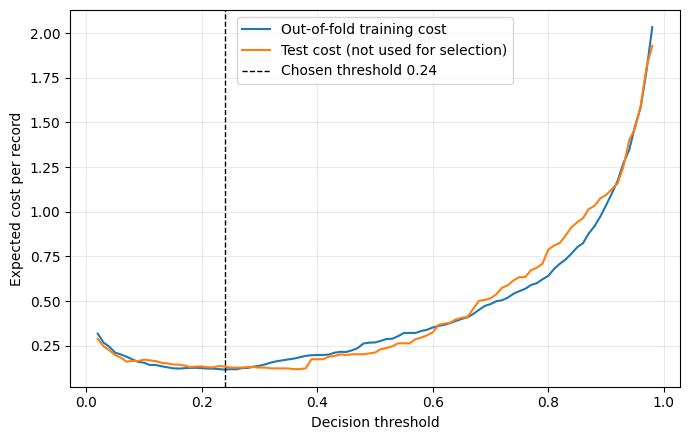

,Model / threshold,Phishing prevalence,TPR,FPR,Precision,False alarms per true detection,"Alerts per 10,000 URLs"
0,"UCI extra trees, 0.50",0.0005,0.9602,0.0426,0.0112,88.5938,430.1199
1,"UCI extra trees, 0.50",0.0100,0.9602,0.0426,0.1856,4.3876,517.2921
2,"UCI extra trees, 0.50",0.0500,0.9602,0.0426,0.5429,0.8421,884.3331
3,"UCI extra trees, 0.50",0.4555,0.9602,0.0426,0.9497,0.0530,4605.2104
4,"UCI extra trees, 0.24",0.0005,0.9815,0.0887,0.0055,180.5501,890.9892
5,"UCI extra trees, 0.24",0.0100,0.9815,0.0887,0.1006,8.9417,975.8131
6,"UCI extra trees, 0.24",0.0500,0.9815,0.0887,0.3682,1.7161,1332.9663
7,"UCI extra trees, 0.24",0.4555,0.9815,0.0887,0.9026,0.1080,4953.6068
8,"8-feature transfer model on PhreshPhish, 0.50",0.0005,0.5570,0.6669,0.0004,2393.3658,6667.9538
9,"8-feature transfer model on PhreshPhish, 0.50",0.0100,0.5570,0.6669,0.0084,118.5309,6657.5152


In [40]:
COST_FN, COST_FP = 10.0, 1.0      # plausible 10:1 ratio; change to match a real deployment and report it
best_cost_model = Pipeline([("imputer", SimpleImputer(strategy="median")),
                            ("model", ExtraTreesClassifier(n_estimators=150, max_depth=20, n_jobs=-1,
                                                           random_state=RANDOM_STATE))])
oof_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_prob = cross_val_predict(best_cost_model, X_train, y_train, groups=groups_train, cv=oof_cv,
                             method="predict_proba")[:, 1]

grid = np.round(np.arange(0.02, 0.99, 0.01), 2)
def expected_cost(yt, prob, thr):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
    return (COST_FN * fn + COST_FP * fp) / len(yt), fp, fn
oof_costs = [expected_cost(y_train.to_numpy(), oof_prob, t)[0] for t in grid]
thr_star = float(grid[int(np.argmin(oof_costs))])
print(f"Threshold chosen on out-of-fold training data: {thr_star:.2f} (default 0.50)")

best_cost_model.fit(X_train, y_train)
test_prob = best_cost_model.predict_proba(X_test)[:, 1]
op_rows = []
for label, thr in [("Default 0.50", 0.5), (f"Cost-minimizing {thr_star:.2f}", thr_star)]:
    pred = (test_prob >= thr).astype(int)
    cost, fp, fn = expected_cost(y_test.to_numpy(), test_prob, thr)
    r = {"Operating point": label, "Threshold": thr, "FP": fp, "FN": fn,
         f"Expected cost per record (FN:FP={COST_FN:g}:{COST_FP:g})": cost}
    r.update({k: v for k, v in metric_row(y_test, pred, test_prob).items() if k in ("Precision", "Recall", "F1", "FPR", "FNR")})
    op_rows.append(r)
operating_points = pd.DataFrame(op_rows)
display(operating_points.round(4))
operating_points.to_csv(f"{REV_DIR}/cost_sensitive_operating_points.csv", index=False)

plt.figure(figsize=(7, 4.5))
plt.plot(grid, oof_costs, label="Out-of-fold training cost")
plt.plot(grid, [expected_cost(y_test.to_numpy(), test_prob, t)[0] for t in grid], label="Test cost (not used for selection)")
plt.axvline(thr_star, color="k", ls="--", lw=1, label=f"Chosen threshold {thr_star:.2f}")
plt.xlabel("Decision threshold"); plt.ylabel("Expected cost per record"); plt.legend(); plt.grid(alpha=.25)
plt.tight_layout(); plt.savefig(f"{REV_DIR}/cost_vs_threshold.png", dpi=300); plt.show()

# Prevalence-adjusted metrics: precision = TPR*pi / (TPR*pi + FPR*(1-pi))
prev_rows = []
for label, thr in [("UCI extra trees, 0.50", 0.5), (f"UCI extra trees, {thr_star:.2f}", thr_star)]:
    pred = (test_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    tpr, fpr = tp / (tp + fn), fp / (fp + tn)
    for pi in [0.0005, 0.01, 0.05, 0.4555]:
        flagged_per_10k = 10000 * (tpr * pi + fpr * (1 - pi))
        prev_rows.append({"Model / threshold": label, "Phishing prevalence": pi, "TPR": tpr, "FPR": fpr,
                          "Precision": tpr * pi / (tpr * pi + fpr * (1 - pi)),
                          "False alarms per true detection": (fpr * (1 - pi)) / (tpr * pi),
                          "Alerts per 10,000 URLs": flagged_per_10k})
if "ext_pred" in globals():
    tn, fp, fn, tp = confusion_matrix(y_ext, ext_pred, labels=[0, 1]).ravel()
    tpr, fpr = tp / (tp + fn), fp / (fp + tn)
    for pi in [0.0005, 0.01, 0.05, 0.4555]:
        prev_rows.append({"Model / threshold": "8-feature transfer model on PhreshPhish, 0.50", "Phishing prevalence": pi,
                          "TPR": tpr, "FPR": fpr, "Precision": tpr * pi / (tpr * pi + fpr * (1 - pi)),
                          "False alarms per true detection": (fpr * (1 - pi)) / (tpr * pi),
                          "Alerts per 10,000 URLs": 10000 * (tpr * pi + fpr * (1 - pi))})
prevalence_df = pd.DataFrame(prev_rows)
display(prevalence_df.round(4))
prevalence_df.to_csv(f"{REV_DIR}/prevalence_adjusted_metrics.csv", index=False)

## 41. Within-source reference and modern URL-based baselines on PhreshPhish

UCI contains no raw URLs, so a character-level or n-gram URL model cannot be trained on UCI. What can be done is to train on a **separate PhreshPhish training sample** and test on the same PhreshPhish test sample used in Section 25. This gives:

1. **Within-source 8-feature reference:** the same eight harmonized features and the same extra-trees configuration, trained on PhreshPhish. If this scores well, the eight features carry signal and the weak UCI-to-PhreshPhish transfer is a shift/mapping problem, not pure feature weakness. If it also scores poorly, feature weakness dominates.
2. **Character n-gram TF-IDF + logistic regression** (lightweight lexical baseline).
3. **Character-level CNN** (needs `torch`, preinstalled on Colab; skipped otherwise).

End-to-end latency (feature extraction/encoding **plus** inference, per URL) is reported so that the efficiency claim can be judged against something other than pre-computed vectors. The train sample is drawn with a seeded shuffle buffer from the streamed `train` split, so it is approximate and is recorded in the metadata. URLs that also occur in the test sample are removed.

In [41]:
# Within-source PhreshPhish baselines (8-feature, TF-IDF, CNN)
def load_phreshphish_train_sample(n=20000, seed=RANDOM_STATE, buffer_size=20000):
    from datasets import load_dataset
    ds = load_dataset("phreshphish/phreshphish", split="train", streaming=True)
    try:
        ds = ds.select_columns(["url", "label", "date"])      # avoid downloading page HTML when possible
    except Exception:
        pass
    ds = ds.shuffle(seed=seed, buffer_size=buffer_size)
    rows = []
    for row in ds:
        label = str(row.get("label", "")).strip().lower()
        url = row.get("url")
        if not url or label not in {"phish", "phishing", "benign", "legitimate"}:
            continue
        rows.append({"url": str(url), "label": 1 if label in {"phish", "phishing"} else 0, "date": str(row.get("date"))})
        if len(rows) >= n:
            break
    df = pd.DataFrame(rows).drop_duplicates(subset=["url"]).reset_index(drop=True)
    return df

def evaluate_url_baselines(train_df, test_df, run_cnn=True, cnn_epochs=3):
    """Train on train_df, evaluate on test_df. Returns a metrics table with end-to-end latency per URL."""
    out = []
    y_tr, y_te = train_df["label"].to_numpy(), test_df["label"].to_numpy()

    # 1) within-source 8-feature extra trees (same features/config as the UCI transfer model)
    t0 = time.perf_counter()
    F_tr = pd.DataFrame([extract_harmonized_url_features(u) for u in train_df["url"]], columns=URL8)
    m8 = Pipeline([("imputer", SimpleImputer(strategy="median")),
                   ("model", ExtraTreesClassifier(n_estimators=250, max_features="sqrt", class_weight="balanced",
                                                  random_state=RANDOM_STATE, n_jobs=-1))]).fit(F_tr, y_tr)
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    F_te = pd.DataFrame([extract_harmonized_url_features(u) for u in test_df["url"]], columns=URL8)
    p8 = m8.predict_proba(F_te)[:, 1]
    lat = 1000 * (time.perf_counter() - t0) / len(test_df)
    r = {"Model": "8-feature extra trees, trained WITHIN PhreshPhish", "Fit seconds": fit_s,
         "End-to-end ms/URL": lat}; r.update(metric_row(y_te, (p8 >= .5).astype(int), p8)); out.append(r)

    # 2) char n-gram TF-IDF + logistic regression
    from sklearn.feature_extraction.text import TfidfVectorizer
    t0 = time.perf_counter()
    tfidf = TfidfVectorizer(analyzer="char", ngram_range=(3, 5), min_df=3, max_features=200000, sublinear_tf=True,
                            lowercase=True, dtype=np.float32)
    A_tr = tfidf.fit_transform(train_df["url"])
    lr = LogisticRegression(max_iter=2000, C=4.0, solver="liblinear").fit(A_tr, y_tr)
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    plr = lr.predict_proba(tfidf.transform(test_df["url"]))[:, 1]
    lat = 1000 * (time.perf_counter() - t0) / len(test_df)
    r = {"Model": "Char 3-5-gram TF-IDF + logistic regression", "Fit seconds": fit_s, "End-to-end ms/URL": lat}
    r.update(metric_row(y_te, (plr >= .5).astype(int), plr)); out.append(r)

    # 3) character-level CNN
    if run_cnn:
        try:
            import torch, torch.nn as nn
            torch.manual_seed(RANDOM_STATE)
            MAXLEN = 200
            def encode(urls):
                arr = np.zeros((len(urls), MAXLEN), dtype=np.int64)
                for i, u in enumerate(urls):
                    b = np.frombuffer(str(u).encode("utf-8", "ignore")[:MAXLEN], dtype=np.uint8)
                    arr[i, :len(b)] = b.astype(np.int64) + 1
                return torch.from_numpy(arr)
            class CharCNN(nn.Module):
                def __init__(self):
                    super().__init__()
                    self.emb = nn.Embedding(257, 32, padding_idx=0)
                    self.conv = nn.Conv1d(32, 128, kernel_size=5, padding=2)
                    self.fc = nn.Linear(128, 1)
                def forward(self, x):
                    h = torch.relu(self.conv(self.emb(x).transpose(1, 2)))
                    return self.fc(h.max(dim=2).values).squeeze(1)
            net = CharCNN(); opt = torch.optim.Adam(net.parameters(), lr=2e-3); lossf = nn.BCEWithLogitsLoss()
            Xtr_t = encode(train_df["url"]); ytr_t = torch.tensor(y_tr, dtype=torch.float32)
            t0 = time.perf_counter()
            for epoch in range(cnn_epochs):
                net.train(); perm = torch.randperm(len(Xtr_t)); tot = 0.0
                for i in range(0, len(perm), 256):
                    idx = perm[i:i + 256]
                    opt.zero_grad(); loss = lossf(net(Xtr_t[idx]), ytr_t[idx]); loss.backward(); opt.step()
                    tot += loss.item() * len(idx)
                print(f"CNN epoch {epoch + 1}/{cnn_epochs}: train loss {tot / len(perm):.4f}")
            fit_s = time.perf_counter() - t0
            net.eval(); t0 = time.perf_counter()
            with torch.no_grad():
                Xte_t = encode(test_df["url"])
                pc = torch.cat([torch.sigmoid(net(Xte_t[i:i + 1024])) for i in range(0, len(Xte_t), 1024)]).numpy()
            lat = 1000 * (time.perf_counter() - t0) / len(test_df)
            r = {"Model": "Character-level CNN", "Fit seconds": fit_s, "End-to-end ms/URL": lat}
            r.update(metric_row(y_te, (pc >= .5).astype(int), pc)); out.append(r)
        except ImportError:
            print("torch not installed: character CNN skipped.")
    return pd.DataFrame(out)

pp_train = load_phreshphish_train_sample()
pp_train = pp_train[~pp_train["url"].isin(set(external_raw["url"]))].reset_index(drop=True)
print("PhreshPhish training sample:", len(pp_train), "| phishing prevalence:", round(pp_train["label"].mean(), 4),
      "| dates:", pp_train["date"].min(), "to", pp_train["date"].max())
pp_train.to_csv(f"{REV_DIR}/phreshphish_train_sample_urls.csv", index=False)   # saved so the sample can be released with the code

url_baselines = evaluate_url_baselines(pp_train, external_raw)
# Reference rows: UCI-trained transfer model, and the same model's end-to-end cost
t0 = time.perf_counter()
_Fx = pd.DataFrame([extract_harmonized_url_features(u) for u in external_raw.url], columns=URL8)
_ = url_only_model.predict_proba(_Fx)[:, 1]
lat_uci = 1000 * (time.perf_counter() - t0) / len(external_raw)
uci_row = {"Model": "8-feature extra trees, trained on UCI (transfer, Section 25)", "Fit seconds": np.nan,
           "End-to-end ms/URL": lat_uci}
uci_row.update(metric_row(y_ext, ext_pred, ext_prob))
url_baselines = pd.concat([pd.DataFrame([uci_row]), url_baselines], ignore_index=True)
display(url_baselines.round(4))
url_baselines.to_csv(f"{REV_DIR}/phreshphish_url_baselines.csv", index=False)

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

PhreshPhish training sample: 20000 | phishing prevalence: 0.4468 | dates: 2024-07-02 to 2025-09-08
CNN epoch 1/3: train loss 0.3188
CNN epoch 2/3: train loss 0.1629
CNN epoch 3/3: train loss 0.1269


,Model,Fit seconds,End-to-end ms/URL,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,MCC,FPR,FNR
0,"8-feature extra trees, trained on UCI (transfe...",NaN,0.0470,0.4351,0.4113,0.5570,0.4732,0.4744,0.4514,-0.1126,0.6669,0.4430
1,"8-feature extra trees, trained WITHIN PhreshPhish",1.5869,0.0364,0.6837,0.7261,0.4907,0.5856,0.7490,0.7025,0.3624,0.1548,0.5093
2,Char 3-5-gram TF-IDF + logistic regression,6.1421,0.1425,0.9194,0.9625,0.8564,0.9064,0.9773,0.9743,0.8404,0.0279,0.1436
3,Character-level CNN,57.1234,0.5146,0.9335,0.9600,0.8911,0.9243,0.9830,0.9817,0.8671,0.0310,0.1089


## 42. Hyperparameter documentation, expanded search, and tree-count / depth ablation

(a) Writes the searched ranges of Section 24 to disk so they can be reported. (b) Optionally runs a larger randomized search (50 candidates) - set `EXPANDED_SEARCH = True`; it is slow on Colab Free. (c) Ablates the number of trees and depth for random forest and extra trees using **group cross-validation on the training partition only** (no test-set snooping).

In [43]:
# Save the hyperparameter search spaces and the selected parameters
def describe_space(v):
    if hasattr(v, "dist") and hasattr(v, "args"):
        return f"{v.dist.name}{tuple(int(a) if float(a).is_integer() else round(float(a), 6) for a in v.args)}"
    return str(v)

space_rows = [{"Model": m, "Parameter": p.replace("model__", ""), "Search space": describe_space(v)}
              for m, sp in search_spaces.items() for p, v in sp.items()]
search_space_df = pd.DataFrame(space_rows)
search_space_df.to_csv(f"{REV_DIR}/hyperparameter_search_spaces.csv", index=False)
display(search_space_df)
selected_df = optimization_df[["Model", "Candidates", "Best CV average precision", "Best parameters"]]
selected_df.to_csv(f"{REV_DIR}/selected_hyperparameters.csv", index=False)
display(selected_df)

,Model,Parameter,Search space
0,Logistic Regression,C,"loguniform(0.001, 100)"
1,Logistic Regression,class_weight,"[None, 'balanced']"
2,Decision Tree,max_depth,"[None, 5, 8, 12, 16, 24, 32]"
3,Decision Tree,min_samples_split,"randint(2, 20)"
4,Decision Tree,min_samples_leaf,"randint(1, 10)"
5,Decision Tree,class_weight,"[None, 'balanced']"
6,Random Forest,n_estimators,"[150, 250, 350]"
7,Random Forest,max_depth,"[None, 10, 16, 24, 32]"
8,Random Forest,min_samples_leaf,"randint(1, 6)"
9,Random Forest,max_features,"['sqrt', 'log2', 0.7]"


,Model,Candidates,Best CV average precision,Best parameters
0,Logistic Regression,8,0.973222,"{'model__C': np.float64(0.9846738873614566), '..."
1,Decision Tree,8,0.964722,"{'model__class_weight': 'balanced', 'model__ma..."
2,Random Forest,8,0.987984,"{'model__class_weight': 'balanced_subsample', ..."
3,Extra Trees,8,0.988748,"{'model__class_weight': 'balanced', 'model__ma..."
4,Hist Gradient Boosting,8,0.989810,{'model__l2_regularization': np.float64(0.0244...
5,Gradient Boosting,8,0.986399,{'model__learning_rate': np.float64(0.18661212...


In [44]:
# Optional expanded randomized search (disabled by default; slow on Colab Free)
EXPANDED_SEARCH = False        # set True for a 50-candidate search (slow)
N_ITER_EXPANDED = 50
if EXPANDED_SEARCH:
    exp_rows, exp_pred = [], {}
    for model_name, distribution in search_spaces.items():
        s = RandomizedSearchCV(models_for_tuning[model_name], distribution, n_iter=N_ITER_EXPANDED,
                               scoring="average_precision", cv=TUNE_CV, random_state=RANDOM_STATE,
                               n_jobs=-1, refit=True)
        s.fit(X_train, y_train, groups=groups_train)
        pr = s.best_estimator_.predict_proba(X_test)[:, 1]
        pd_ = s.best_estimator_.predict(X_test)
        r = {"Model": model_name, "Candidates": N_ITER_EXPANDED, "Best CV AP": s.best_score_,
             "Best parameters": str(s.best_params_)}
        r.update(metric_row(y_test, pd_, pr)); exp_rows.append(r)
        print(model_name, "done")
    expanded_df = pd.DataFrame(exp_rows)
    display(expanded_df.round(4))
    expanded_df.to_csv(f"{REV_DIR}/expanded_search_{N_ITER_EXPANDED}_candidates.csv", index=False)
else:
    print("EXPANDED_SEARCH is False: skipped. State the 8-candidate budget as a limitation if you keep it.")

EXPANDED_SEARCH is False: skipped. State the 8-candidate budget as a limitation if you keep it.


In [45]:
# Tree-count / depth ablation on the training partition (group-aware 5-fold CV, F1)
abl_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
abl_rows = []
for fam, Est in [("Random Forest", RandomForestClassifier), ("Extra Trees", ExtraTreesClassifier)]:
    for n_est in [50, 100, 150, 300]:
        for depth in [10, 20, None]:
            pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                             ("model", Est(n_estimators=n_est, max_depth=depth, n_jobs=-1, random_state=RANDOM_STATE))])
            sc = cross_validate(pipe, X_train, y_train, groups=groups_train, cv=abl_cv,
                                scoring={"f1": "f1", "roc_auc": "roc_auc"}, n_jobs=1)
            abl_rows.append({"Model": fam, "n_estimators": n_est, "max_depth": "None" if depth is None else depth,
                             "CV F1 mean": sc["test_f1"].mean(), "CV F1 sd": sc["test_f1"].std(ddof=1),
                             "CV ROC-AUC mean": sc["test_roc_auc"].mean()})
ablation_df = pd.DataFrame(abl_rows)
display(ablation_df.round(4))
ablation_df.to_csv(f"{REV_DIR}/tree_count_depth_ablation.csv", index=False)

,Model,n_estimators,max_depth,CV F1 mean,CV F1 sd,CV ROC-AUC mean
0,Random Forest,50,10,0.9336,0.0089,0.9890
1,Random Forest,50,20,0.9439,0.0080,0.9908
2,Random Forest,50,None,0.9445,0.0102,0.9908
3,Random Forest,100,10,0.9320,0.0112,0.9894
4,Random Forest,100,20,0.9453,0.0097,0.9911
5,Random Forest,100,None,0.9442,0.0086,0.9913
6,Random Forest,150,10,0.9331,0.0102,0.9895
7,Random Forest,150,20,0.9454,0.0095,0.9912
8,Random Forest,150,None,0.9434,0.0082,0.9916
9,Random Forest,300,10,0.9346,0.0104,0.9895


## 43. Run record, README, and results bundle

Writes a metadata addendum (seeds, folds, thresholds, sample sizes, package versions) and a `README.md` that documents the pipeline. When publishing the work, upload this notebook, the `research_results/` folder, and the sampled-URL CSVs to the repository.

In [46]:
# Run record and README for the code repository
import json
addendum = {
    "seeds": SEEDS,
    "outer_folds_evaluated_for_sensitivity": [0, 1, 2, 3, 4],
    "conflicting_groups_excluded": len(conflict_groups_set),
    "rows_after_excluding_conflicts": int(len(X_clean)),
    "cost_ratio_fn_to_fp": [COST_FN, COST_FP],
    "threshold_chosen_on_oof_training": thr_star,
    "paired_test": "group-level sign-flip permutation test, 20000 permutations, Holm correction",
    "phreshphish_test_sample_n": int(len(external_raw)),
    "phreshphish_train_sample_n": int(len(pp_train)) if "pp_train" in globals() else None,
    "expanded_search_run": bool(EXPANDED_SEARCH),
    "python_version": platform.python_version(), "sklearn_version": sklearn.__version__,
    "shap_version": shap.__version__, "platform": platform.platform(), "cpu_count": os.cpu_count(),
}
with open(f"{REV_DIR}/revision_metadata.json", "w") as f:
    json.dump(addendum, f, indent=2)
# Release the exact PhreshPhish test sample too, so it can be verified independently.
external_raw.to_csv(f"{REV_DIR}/phreshphish_test_sample_urls.csv", index=False)

readme = """# Phishing detection: leakage-aware evaluation with cross-source transfer testing

Pipeline (run `Explainable_Phishing_Detection_Q1_Enhanced.ipynb` top to bottom, Colab CPU is sufficient):
1. Sections 1-23: UCI data (repository ID 327), duplicate/conflict audit, group-aware split (StratifiedGroupKFold, 5 folds, fold 0 = test), baseline models, SHAP, bootstrap, McNemar, calibration, timing.
2. Section 24: randomized search (8 candidates; ranges in research_results/revision/hyperparameter_search_spaces.csv).
3. Section 25: PhreshPhish URL-only transfer test (seeded reservoir sample, seed 42; the sample is in research_results/revision/phreshphish_test_sample_urls.csv).
4. Sections 26-33: SHAP stability, cluster bootstrap, conflicting-label sensitivity.
5. Sections 34-43 (revision): multi-seed runs, eight-feature UCI baseline, outer-fold sensitivity, conflict exclusion, group-aware paired tests, SHAP stability baselines, cost-sensitive thresholds, URL baselines, ablations.

Outputs: research_results/*.csv and research_results/revision/*.csv|png|json.
Environment: see research_results/experiment_metadata.json and revision_metadata.json.
"""
with open("research_results/README.md", "w") as f:
    f.write(readme)
print(json.dumps(addendum, indent=2))

{
  "seeds": [
    42,
    7,
    11,
    23,
    101,
    202,
    303,
    404,
    505,
    606
  ],
  "outer_folds_evaluated_for_sensitivity": [
    0,
    1,
    2,
    3,
    4
  ],
  "conflicting_groups_excluded": 64,
  "rows_after_excluding_conflicts": 10698,
  "cost_ratio_fn_to_fp": [
    10.0,
    1.0
  ],
  "threshold_chosen_on_oof_training": 0.24,
  "paired_test": "group-level sign-flip permutation test, 20000 permutations, Holm correction",
  "phreshphish_test_sample_n": 10000,
  "phreshphish_train_sample_n": 20000,
  "expanded_search_run": false,
  "python_version": "3.13.18",
  "sklearn_version": "1.6.1",
  "shap_version": "0.54.1",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "cpu_count": 2
}


In [47]:
# Archive the full results folder (including revision outputs) as a ZIP file
import shutil
shutil.make_archive("phishing_research_results_revised", "zip", root_dir="research_results")
try:
    from google.colab import files
    files.download("phishing_research_results_revised.zip")
except ImportError:
    print("Not running in Colab: ZIP saved in the current directory.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>